# E94 · Ragged information: polls, fundamentals and money in the US midterms

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: US House and Senate races 2016-2026. Results, candidate reports and independent expenditures from the **FEC** (results workbooks and bulk files, public domain); polls, partisan lean and historical poll errors from **FiveThirtyEight** (CC BY 4.0); House returns 2004-2014 from **MEDSL** (GitHub copy, treated as CC0); 2026 nominees, Cook PVI, race polls and weekly aggregator averages from **Wikipedia** as of 2026-11-02 (CC BY-SA 4.0). Seven derived files and three JSON records (build log and two frozen forecasts), 2.3 MB |
| **You will learn** | Forecasting from **ragged information**: many national polls, few district polls, fundamentals everywhere · a **midterm prior** and a weekly **reverse random walk** with house effects and a **shared polling error**, rotated to be sampleable · fundamentals learned on **earlier cycles only**, with **state effects** shared by House and Senate · **backtests** of 2018 and 2022 against three simpler forecasts · **Jacobson's paradox** and **Levitt's rematches** for the effect of spending · **nowcasting campaign spending** from lagged FEC filings, with a **reporting-lag** model and a hierarchical **late-spending** model · a 2026 forecast **frozen** before the polls closed, and the code that will **score it later** · **predictive draws** as an animated map, and the forecast's **sensitivity** to a polling error that favours one party |

## The setting

It is election day, 3 November 2026, and the polls have not closed. This notebook makes two forecasts
on information that ends on 2 November: who wins the 435 House seats and 35 Senate races, and how much
the campaigns will turn out to have spent. Both are written to a file before any result exists, and the
notebook ends with the code that will score them.

Information about an election arrives unevenly. A midterm has hundreds of national **generic-ballot**
polls ("would you vote for the Democrat or the Republican for Congress?"), a few hundred Senate polls,
and polls in perhaps a quarter of the House districts, many paid for by a party or a campaign. What
every district does have is **fundamentals**: its partisan lean, whether an incumbent runs, how much
money each side has raised, and the habit of voters turning against the president's party in a
midterm (Abramowitz 2010). Poll aggregators combine polls with fundamentals (Linzer 2013; Heidemanns,
Gelman and Morris 2020). The idea that ties it together is partial pooling: each source speaks where it
exists, the fundamentals carry the rest, and errors are shared where they really are shared.

E40 built a poll aggregator for the 2016 presidential election: a reverse random walk, pollster house
effects and a shared polling error, rotated to be sampleable. This notebook builds on it without
repeating its derivations. What is new is the ragged picture, backtests on two midterms, and money.

Money enters in three roles. As a **forecast signal**, the ratio of the two candidates' receipts
predicts the vote beyond lean and incumbency. As a **cause**, it is mostly confounded: Jacobson (1978,
1990) found that incumbents who spend more do worse, because money follows close races, and Levitt
(1994) used rematches between the same two candidates to find a small effect. As a **quantity to
nowcast**, total spending through election day is not known on election day, because candidates report
their October spending a month later. This is the problem of nowcasting an epidemic from delayed case
reports (E38; Höhle and an der Heiden 2014), with dollars instead of cases.

| part | question | tool |
|---|---|---|
| 1 | What data exist, and what was checked? | FEC, FiveThirtyEight, MEDSL and Wikipedia, cut at each eve |
| 2 | What information exists, and where? | polls per race against partisan lean |
| 3 | The national environment | a midterm prior, a weekly reverse random walk, a shared polling error; a rotation (failure 1) |
| 4 | Do the forecasts hold up? | backtests of 2018 and 2022: the full model against aggregate-only, polls-only and fundamentals-only |
| 5 | Does money buy votes? | Jacobson's paradox (failure 2); Levitt's rematches with hierarchical slopes |
| 6 | How much was spent? | the spending curve, a reporting-lag model for outside money, a late-spending model (failure 3), backtests |
| 7 | 2026 | two frozen forecasts (pre-registered and corrected), an animated map of predictive draws, the forecast if Democrats fall short of their polls, spending nowcasts |
| 8 | Scoring 2026, later | the scorer, exercised on 2018 and 2022; "not yet available" for 2026 |

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain
os.environ.setdefault("JAX_PLATFORMS", "cpu")  # nothing here uses a GPU

import gzip
import hashlib
import json
import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from IPython.display import HTML
from matplotlib import animation
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

from pymc_challenges import data

# ArviZ leaves a lazy stub under "jax", and Matplotlib's first plot tests it, which would import all of
# JAX for nothing (see E89). Nothing here uses JAX, so the stub goes.
sys.modules.pop("jax", None)

RANDOM_SEED = 94
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*sample_stats.*")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
T_START = time.time()

D_C, R_C, INK, MUTED, LIGHT, GOLD = "#2166ac", "#c0392b", "#222222", "#8a8a8a", "#d9d9d9", "#e08e0b"
EVE = {2018: "2018-11-05", 2022: "2022-11-07", 2026: "2026-11-02"}      # last day of information
ELEC = {2018: "2018-11-06", 2022: "2022-11-08", 2026: "2026-11-03"}
END_30G = {2018: "2018-11-26", 2022: "2022-11-28", 2026: "2026-11-23"}  # post-general coverage ends
PRES = {1978: "D", 1982: "R", 1986: "R", 1990: "R", 1994: "D", 1998: "D", 2002: "R", 2006: "R",
        2010: "D", 2014: "D", 2018: "R", 2022: "D", 2026: "R"}         # president's party at each midterm
TRAIN = {2018: [2016], 2022: [2016, 2018, 2020], 2026: [2016, 2018, 2020, 2022]}
TIMES = {}

## 1 · The data

Everything comes from public sources and was processed by `tools/build_e94_data.py` from raw downloads
into small files. Every result in a backtest uses only what was public by the evening before the
election: **5 November 2018, 7 November 2022 and 2 November 2026**. Polls are kept only if
FiveThirtyEight had entered them by the eve, FEC reports and independent expenditures by the date the
FEC received them, and the 2026 Wikipedia tables at their last revision on or before 2 November.

Some things could not be had. No openly licensed list of individual 2026 national polls exists, so 2026
uses weekly snapshots of the aggregator averages on Wikipedia (Decision Desk HQ, RealClearPolitics,
Silver Bulletin and others): averages, not polls. MEDSL's current House data sit behind a guestbook, so
its older GitHub copy is used for 2004-2014 only. The FEC report file keeps only the latest version of
each report, so a report amended after the eve drops out of "known by the eve" (1-2% of pre-general
reports).

In [2]:
for name in ("e94_races", "e94_polls", "e94_reports", "e94_ie", "e94_rematch", "e94_pollerr"):
    data.describe(name)
    print()

e94_races: One row per race: cycle (2016-2026), office (H/S), state, race (e.g. PA-07, OH-S, MN-S2 for a special), region (Census), special, seat (counts toward the next Congress), lean (D-minus-R points on the margin scale: 538 lean for 2016-2022, 2 x Cook PVI for 2026; blank where the lines differ), pvi (2026), inc_party (D, R or blank for an open seat), open, d_inc, r_inc, d_id/r_id (FEC candidate IDs) and names of the top D-side and R candidates, d_is_ind (independent on the D side), contested (both sides on the ballot), split (jungle-style ballot), dem2 (D share of the two-party vote; blank for 2026), winner, rcv (ranked-choice final round used), d_votes, r_votes, *_rec_eve / *_disb_eve / *_coh_eve (receipts, disbursements, cash on hand in reports the FEC had received by the eve: 2018-11-05, 2022-11-07, 2026-11-02), *_rec_final / *_disb_final (cycle totals from weball), member and status (2026), multi_cands (2026: several candidates of one side on the November ballot, as in Louisi

In [3]:
races = data.load("e94_races")
polls = data.load("e94_polls")
reports = data.load("e94_reports")
ie = data.load("e94_ie")
rematch = data.load("e94_rematch")
pollerr = data.load("e94_pollerr")
build_log = json.load(open(data.path("e94_build_log")))
for c in ("cvg_start", "cvg_end", "receipt"):
    reports[c] = pd.to_datetime(reports[c])
for c in ("date", "first_receipt"):
    ie[c] = pd.to_datetime(ie[c])
polls["end"] = pd.to_datetime(polls["end"])

NAT = {int(k): v for k, v in build_log["national_house_dem2"].items()}
NAT.update({int(k): v for k, v in build_log["national_house_dem2_medsl"].items() if int(k) < 2016})
MARGIN = {y: 100 * (2 * v - 1) for y, v in NAT.items()}          # national House margin, D minus R
MARGIN_2024 = 100 * (2 * build_log["national_house_2024_wikipedia"]["dem2"] - 1)


def money_signal(df):
    """log((D receipts + $50k) / (R receipts + $50k)): eve totals where reports exist, else cycle totals.

    A candidate with an FEC ID and nothing reported counts as $0. A 2026 nominee with no FEC ID found is
    missing (NaN), not $0: the model imputes the signal (see prepare)."""
    eve = df.cycle.isin([2018, 2022, 2026]).to_numpy()
    d = np.where(eve, df.d_rec_eve, df.d_rec_final).astype(float)
    r = np.where(eve, df.r_rec_eve, df.r_rec_final).astype(float)
    miss = (df.cycle == 2026).to_numpy() & (np.isnan(d) | np.isnan(r))
    out = np.clip(np.log((np.nan_to_num(d) + 5e4) / (np.nan_to_num(r) + 5e4)), -5, 5)
    return np.where(miss, np.nan, out)


R = races.copy()
R["inc"] = np.where(R.d_inc, 1.0, np.where(R.r_inc, -1.0, 0.0))
R["money"] = money_signal(R)
R["m"] = 100 * (2 * R.dem2 - 1)                                   # D minus R margin, points
R["leanx"] = R.lean / 10
R["modelled"] = R.seat & R.contested & ~R.split
print(R.groupby(["cycle", "office"]).agg(races=("race", "size"), contested=("contested", "sum"),
                                         modelled=("modelled", "sum")).T.to_string())

cycle     2016     2018     2020     2022     2026    
office       H   S    H   S    H   S    H   S    H   S
races      435  34  435  35  435  35  435  36  435  35
contested  377  33  393  34  407  35  404  35  416  35
modelled   371  31  391  33  403  33  403  33  416  35


A race is **modelled** when it counts toward the next Congress, has both a Democrat (or an independent
on the Democratic side) and a Republican on the ballot, and is not a jungle ballot. That leaves 424
races in 2018, 436 in 2022 and 451 in 2026. The others are settled before any vote: a district with only
one party on the ballot (California's top-two system often produces two Democrats) is certain, and the
few jungle-style ballots (Louisiana's, Mississippi's 2018 Senate special and a handful of others) are
called by their lean, which gets every one of them right in 2018 and 2022.

**Lean** is the race's partisan lean relative to the nation, on the margin scale: FiveThirtyEight's for
2016-2022, twice Cook's Partisan Voting Index for 2026. The builder's checks of that scale and of the
FEC IDs are printed below.

In [4]:
chk = build_log["checks"]
lc = chk["lean538_2022_vs_2xcook_pvi"]
print(f"2022 lean (538) against 2 x Cook PVI on {lc['n']} unchanged districts: slope {lc['slope']:.2f}, "
      f"intercept {lc['intercept']:+.1f}, correlation {lc['corr']:.3f}, residual sd {lc['resid_sd']:.1f} points")
sl = chk["state_lean_proxy_vs_538_2018"]
print(f"state lean as the mean of district leans, 2018: correlation {sl['corr']:.3f} with 538's, "
      f"mean absolute difference {sl['mean_abs_diff']:.1f}")
print(f"2026 nominees of contested races with an FEC ID found: D {chk['fec_id_2026_name_match_rate']['d']:.1%}, "
      f"R {chk['fec_id_2026_name_match_rate']['r']:.1%}; not found: {chk['fec_id_2026_unmatched']['r'] + chk['fec_id_2026_unmatched']['d']}")
for c in (2018, 2022, 2026):
    p = chk[f"ie_{c}_prank_spenders"]
    print(f"IE {c}: {p['spenders']} prank spender(s) dropped, ${p['dollars'] / 1e9:,.1f}B claimed")

2022 lean (538) against 2 x Cook PVI on 368 unchanged districts: slope 0.97, intercept -0.2, correlation 0.998, residual sd 2.2 points
state lean as the mean of district leans, 2018: correlation 0.998 with 538's, mean absolute difference 0.9
2026 nominees of contested races with an FEC ID found: D 100.0%, R 99.6%; not found: ['KY-03: Maria Rodriquez', 'MD-04: George McDermott']
IE 2018: 0 prank spender(s) dropped, $0.0B claimed
IE 2022: 1 prank spender(s) dropped, $20.0B claimed
IE 2026: 2 prank spender(s) dropped, $14.0B claimed


FEC IDs for the 2026 nominees are matched by state, office, district and name against the FEC's
candidate list. A nominee without a match has unknown receipts, not zero: an earlier build set them to
\$0, which pinned the money signal of 61 races at its extreme, and section 7 shows what that did to the
first frozen forecast. The two nominees still unmatched get a money signal imputed inside the model,
from a regression on lean, incumbency and office in the other 2026 races.

## 2 · What information exists, and where

Before any model, look at what is known about each race on the eve. For every modelled race we count the
race polls in FiveThirtyEight's database (2018, 2022) or in the race's Wikipedia article (2026), and
mark races whose polls all come from a campaign, a party or a partisan pollster.

In [5]:
def race_poll_table(cycle):
    """Polls per modelled race in the cycle (created or ending by the eve), and whether all are partisan."""
    tg = R[(R.cycle == cycle) & R.modelled][["race", "office", "lean"]].copy()
    p = polls[(polls.cycle == cycle) & polls.kind.isin(["house", "senate"])]
    part = p.partisan.notna() | p.internal
    g = pd.DataFrame({"n": p.groupby("race").size(), "n_ind": (~part).groupby(p.race).sum()})
    tg = tg.join(g, on="race").fillna({"n": 0, "n_ind": 0})
    tg["kind"] = np.where(tg.n == 0, "none", np.where(tg.n_ind == 0, "partisan only", "independent"))
    return tg


rag = {c: race_poll_table(c) for c in (2018, 2022, 2026)}
rows = []
for c, t in rag.items():
    nat_kind = "generic_avg" if c == 2026 else "generic"
    nat = polls[(polls.cycle == c) & (polls.kind == nat_kind)]
    for off in ("S", "H"):
        s = t[t.office == off]
        rows.append({"cycle": c, "office": off, "national polls" if True else "": len(nat),
                     "races": len(s), "with a poll": int((s.n > 0).sum()),
                     "partisan only": int((s.kind == "partisan only").sum()),
                     "polls": int(s.n.sum()),
                     "close races (|lean| < 10)": int((s.lean.abs() < 10).sum()),
                     "close and unpolled": int(((s.lean.abs() < 10) & (s.n == 0)).sum())})
rag_tab = pd.DataFrame(rows)
print(rag_tab.to_string(index=False))
print("2026 national rows are weekly snapshots of aggregator averages, not individual polls")

 cycle office  national polls  races  with a poll  partisan only  polls  close races (|lean| < 10)  close and unpolled
  2018      S             978     33           31              1    547                         12                   0
  2018      H             978    391          146             21    560                         74                  22
  2022      S            1221     33           28              0    608                         10                   0
  2022      H            1221    403          102             33    246                         83                  17
  2026      S             308     35           24              3    543                          9                   1
  2026      H             308    416           97             42    281                         70                  30
2026 national rows are weekly snapshots of aggregator averages, not individual polls


The table is the ragged picture in numbers. Nearly every Senate race has polls, often dozens: 31 of 33
in 2018 and 28 of 33 in 2022. In the House, polls reached 146 of 391 contested districts in 2018, 102 of
403 in 2022 and 97 of 416 in 2026, and many of those had only partisan polls (21, 33 and 42). Even among
the close districts, with a lean within 10 points, 22 of 74 had no poll in 2018 and 30 of 70 have none
in 2026. The 2026 national "polls" are 308 weekly snapshots of seven aggregators' averages (123 in the
last 22 weeks, which the model uses), a different and weaker kind of information, as section 4 measures.

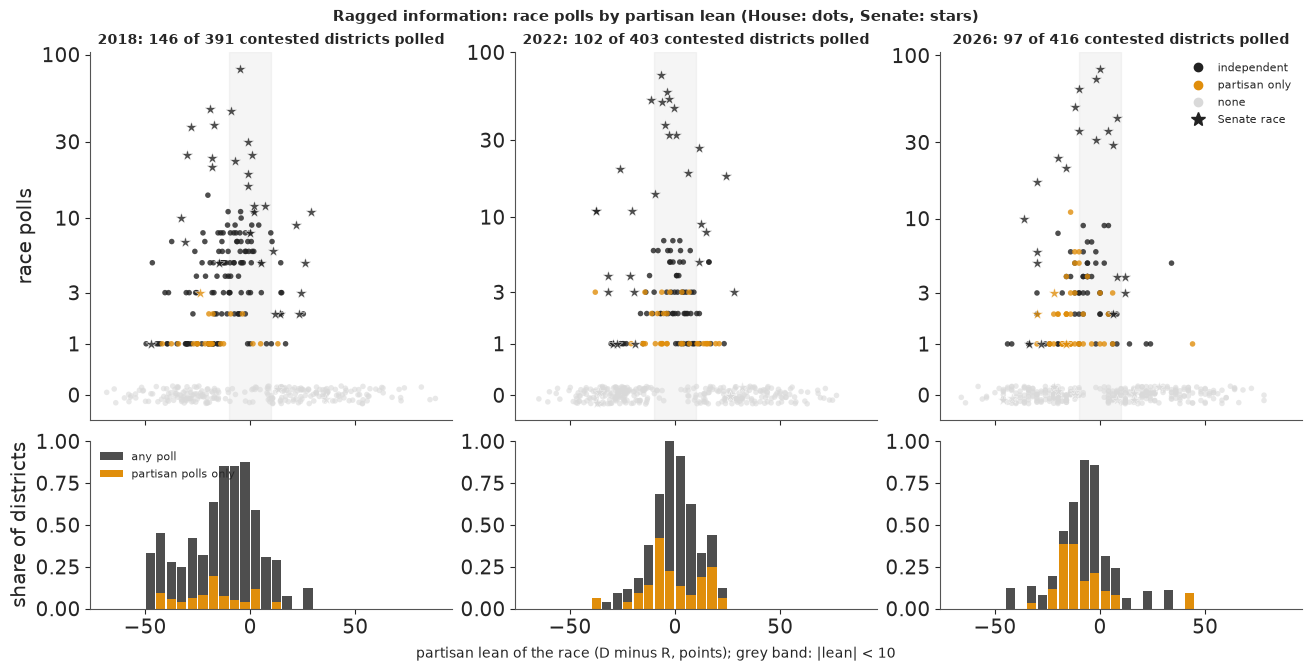

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.6), sharex=True, height_ratios=[2.2, 1])
cols = {"independent": INK, "partisan only": GOLD, "none": LIGHT}
for j, (c, t) in enumerate(rag.items()):
    ax = axes[0, j]
    for off, mk, sz in (("H", "o", 16), ("S", "*", 70)):
        for k, col in cols.items():
            s = t[(t.office == off) & (t.kind == k)]
            y = np.log1p(s.n) + (rng.uniform(-0.12, 0.12, len(s)) if k == "none" else 0)
            ax.scatter(s.lean, y, s=sz, marker=mk, color=col, alpha=0.8 if k != "none" else 0.6,
                       edgecolor="none" if off == "H" else "white", linewidth=0.4)
    ax.set_yticks(np.log1p([0, 1, 3, 10, 30, 100]), ["0", "1", "3", "10", "30", "100"])
    ax.set_title(f"{c}: {int((t[t.office == 'H'].n > 0).sum())} of {int((t.office == 'H').sum())} "
                 f"contested districts polled", fontsize=10)
    ax.axvspan(-10, 10, color=LIGHT, alpha=0.25, zorder=-1)
    ax.set_ylabel("race polls" if j == 0 else "")
    ax2 = axes[1, j]
    h = t[t.office == "H"]
    bins = np.arange(-60, 61, 5)
    cut = pd.cut(h.lean.clip(-59.9, 59.9), bins)
    share = h.groupby(cut, observed=False).apply(lambda s: (s.n > 0).mean() if len(s) else np.nan)
    part = h.groupby(cut, observed=False).apply(lambda s: (s.kind == "partisan only").mean() if len(s) else np.nan)
    mids = bins[:-1] + 2.5
    ax2.bar(mids, share.to_numpy(), width=4.4, color=INK, alpha=0.8, label="any poll")
    ax2.bar(mids, part.to_numpy(), width=4.4, color=GOLD, label="partisan polls only")
    ax2.set_ylim(0, 1)
    ax2.set_ylabel("share of districts" if j == 0 else "")
axes[1, 0].legend(fontsize=8, loc="upper left")
handles = [Line2D([], [], marker="o", ls="", color=cols[k], label=k) for k in cols]
handles += [Line2D([], [], marker="*", ls="", color=INK, ms=10, label="Senate race")]
axes[0, 2].legend(handles=handles, fontsize=8, loc="upper right")
fig.supxlabel("partisan lean of the race (D minus R, points); grey band: |lean| < 10", fontsize=10)
fig.suptitle("Ragged information: race polls by partisan lean (House: dots, Senate: stars)", fontsize=11);

The figure shows where the polls go. They cluster around a lean of zero, where races are competitive,
and thin out quickly beyond 20 points either way: pollsters, like donors, go where the race is close.
The bottom row shows the share of districts with any poll, and the share with only partisan polls, by
lean. Even in the competitive middle a third to a half of districts are unpolled, and in 2026 the
partisan-only share in the middle is large. A forecast must say something about every district, so the
fundamentals do most of the work in most places, and the model has to know how far to trust them.

## 3 · The national environment

### 3.1 A prior from the midterm penalty

The president's party almost always loses ground in a midterm. Measured as the change in the national
House margin (D minus R share of the two-party vote, in points) from the previous election, the swing
against the president's party averaged about 7 points over the midterms since 1978, with a standard
deviation of about 6. Before any poll, a sensible forecast for the national margin $N$ is the previous
margin plus that swing, in the direction against the president:

$$
N \sim \mathcal{N}\big(m_{\text{prev}} + s\,\bar\Delta,\ \sigma_\Delta\big),\qquad
s = +1 \text{ under a Republican president}, -1 \text{ under a Democrat},
$$

with $\bar\Delta$ and $\sigma_\Delta$ computed only from midterms **before** the target, so the 2018
prior uses 1978-2014 and the 2026 prior uses 1978-2022. The national votes come from MEDSL before 2016
and the FEC from 2016 (Wikipedia's results table for 2024).

Two more scales come from history. **Polls share an error**: in some years nearly all of them miss in
the same direction, and that error is not reduced by averaging. FiveThirtyEight's pollster-ratings file
records the error of every late poll since 1998; the mean error of the generic and Senate polls in each
cycle gives a prior sd for the shared error, and the spread of race-level means around their cycle's
mean gives a prior sd for a race's own polling error.

In [7]:
def midterm_prior(target):
    """Previous House margin plus the mean swing against the president's party in earlier midterms."""
    sw = {y: (MARGIN[y] - MARGIN[y - 2]) * (1 if PRES[y] == "R" else -1)
          for y in PRES if y < target and y in MARGIN and y - 2 in MARGIN}
    prev = MARGIN_2024 if target == 2026 else MARGIN[target - 2]
    s = np.array(list(sw.values()))
    sign = 1 if PRES[target] == "R" else -1
    return {"prev": prev, "swings": sw, "mu": prev + sign * s.mean(), "sd": s.std(ddof=1),
            "mean_swing": s.mean(), "n": len(s)}


def poll_error_scales(target):
    """Shared and race-level polling-error scales from FiveThirtyEight's raw polls of earlier cycles."""
    pe = pollerr[pollerr.cycle < target]
    gen = pe[pe.generic].groupby("cycle").err.mean()
    sen = pe[~pe.generic & (pe.type_simple == "Sen-G")]
    sen_cyc = sen.groupby("cycle").err.mean()
    shared = float(np.sqrt(np.mean(np.r_[gen.to_numpy(), sen_cyc.to_numpy()] ** 2)))
    race = float((sen.err - sen.cycle.map(sen_cyc)).std())
    return {"shared": shared, "race": race, "n_cycles": len(gen) + len(sen_cyc)}


PRIOR = {c: midterm_prior(c) for c in (2018, 2022, 2026)}
PERR = {c: poll_error_scales(c) for c in (2018, 2022, 2026)}
for c in PRIOR:
    p, e = PRIOR[c], PERR[c]
    print(f"{c}: previous margin {p['prev']:+.1f}, mean swing against the president's party "
          f"{p['mean_swing']:.1f} (sd {p['sd']:.1f}, {p['n']} midterms) -> N ~ Normal({p['mu']:+.1f}, {p['sd']:.1f}); "
          f"poll error sd: shared {e['shared']:.1f}, race {e['race']:.1f}")
print("actual national margin: 2018 %+.1f, 2022 %+.1f" % (MARGIN[2018], MARGIN[2022]))
v = np.array(list(PRIOR[2026]["swings"].values()))
print(f"swings 1978-2022 range from {v.min():+.1f} to {v.max():+.1f}")

2018: previous margin -1.1, mean swing against the president's party 6.8 (sd 6.5, 10 midterms) -> N ~ Normal(+5.7, 6.5); poll error sd: shared 3.2, race 5.8
2022: previous margin +2.5, mean swing against the president's party 7.1 (sd 6.2, 11 midterms) -> N ~ Normal(-4.6, 6.2); poll error sd: shared 3.4, race 5.6
2026: previous margin -2.6, mean swing against the president's party 7.0 (sd 5.9, 12 midterms) -> N ~ Normal(+4.3, 5.9); poll error sd: shared 3.3, race 5.7
actual national margin: 2018 +8.8, 2022 -2.7
swings 1978-2022 range from -3.8 to +17.8


The three priors differ mostly in their centre. In 2018 a Republican president and a previous margin of
R+1.1 give D+5.7; in 2022 a Democratic president and D+2.5 give R+4.6; in 2026 a Republican president
and R+2.6 give D+4.3. All three are wide (sd 6-6.5 points), which is honest: the swing has ranged from
about -4 to +18. The actual margins were D+8.8 in 2018 and R+2.7 in 2022, both well inside. The
polling-error scales are steady across cycles: about 3.3 points shared, about 5.7 points for a race.

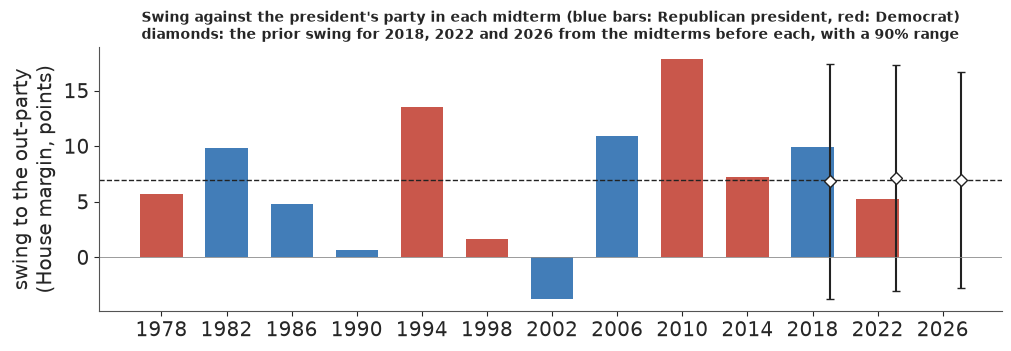

In [8]:
sw = PRIOR[2026]["swings"]
fig, ax = plt.subplots(figsize=(10, 3.4))
yrs = list(sw)
ax.bar(yrs, [sw[y] for y in yrs], width=2.6, color=[D_C if PRES[y] == "R" else R_C for y in yrs], alpha=0.85)
ax.axhline(np.mean(list(sw.values())), color=INK, lw=1, ls="--")
for c in (2018, 2022, 2026):
    p = PRIOR[c]
    sign = 1 if PRES[c] == "R" else -1
    ax.errorbar(c + 1.1, sign * (p["mu"] - p["prev"]), yerr=1.64 * p["sd"], fmt="D", color=INK, mfc="white", capsize=3)
ax.axhline(0, color=MUTED, lw=0.6)
ax.set_xticks(yrs + [2026])
ax.set_ylabel("swing to the out-party\n(House margin, points)")
ax.set_title("Swing against the president's party in each midterm (blue bars: Republican president, red: Democrat)\n"
             "diamonds: the prior swing for 2018, 2022 and 2026 from the midterms before each, with a 90% range",
             fontsize=10);

In the figure, the diamonds sit a year to the right of their bars. The 2018 and 2022 swings (about 10
and 5 points) fell within 3 points of the long-run mean. The fundamentals-only backtest in section 4 is
this prior pushed through the race model, which makes it the prior predictive check for seats.

### 3.2 The model

The national margin is tied to the polls through a weekly walk, as in E40 but in one dimension. Weeks
are counted back from the election ($w = 0$ is election week), and the walk is anchored at the target:

$$
\nu_0 = N,\qquad \nu_w = N + \sigma_{\text{rw}} \textstyle\sum_{k=1}^{w} z_k,\qquad z_k \sim \mathcal N(0,1).
$$

A generic poll $j$ in week $w_j$ by pollster $p_j$ measures the walk plus the shared error $b$ and the
pollster's house effect, with its binomial standard error plus an excess noise $\tau$:

$$
y_j \sim \mathcal N\big(\nu_{w_j} + b + h_{p_j},\ \sqrt{\mathrm{se}_j^2 + \tau^2}\big),\qquad
b \sim \mathcal N(0, \sigma_b),\qquad h \sim \text{ZeroSumNormal}(\sigma_h).
$$

A race $i$ of office $o$ (House or Senate) in state $s$ has margin

$$
m_i = N + \gamma_o + s_{\text{int}} z_o + \beta_o^{\top} x_i + s_{\text{state}}\, u_{s} + \sigma_o \varepsilon_i,
\qquad x_i = (\text{lean}/10,\ \text{incumbent},\ \text{money}),
$$

where incumbent is +1 for a Democratic incumbent, -1 for a Republican and 0 for an open seat, and money
is $\log\big((D + \$50\text{k})/(R + \$50\text{k})\big)$ for the receipts each side had reported by the
eve. The state effect $u_s$ is shared by every House district in a state and by its Senate race: the
model's correlated race error, on top of $N$, which moves every race.

The coefficients $\beta_o$, $\gamma_o$, the residual scales $\sigma_o$ and the scales of the cycle and
state effects are learned from **earlier cycles only**: 2016 for the 2018 forecast, 2016-2020 for 2022
and 2016-2022 for 2026 (the target cycle contributes polls, never results). In those cycles $N$ is
known, so the same equation is a regression with $N_c$ plugged in, fitted in the same model. A race poll
$k$ of race $i$ measures

$$
y_k \sim \mathcal N\big(m_i + (\nu_{w_k} - N) + b + b^{\text{race}}_i + h_{p_k} + \delta\,\text{sponsor}_k,\
\sqrt{\mathrm{se}_k^2 + \tau_r^2}\big),
$$

the race's margin, moved by the national walk in the poll's week, plus the shared error, a race-level
polling error with the historical scale, the pollster's house effect and a sponsor effect $\delta$ for
polls marked D (+1) or R (-1). Only polled races carry a margin in the sampler; every other race is
simulated afterwards from the posterior. Seats follow by counting, per draw.

In [9]:
def prepare(target, mode="full"):
    """Training races (earlier cycles), target races, national and race polls for one target cycle."""
    train = R[R.cycle.isin(TRAIN[target]) & R.modelled & R.lean.notna()]
    tgt = R[(R.cycle == target) & R.seat].copy()
    tm = tgt[tgt.modelled].reset_index(drop=True)
    P = polls[polls.cycle == target].copy()
    P["week"] = ((pd.Timestamp(ELEC[target]) - P.end).dt.days // 7).astype(int)
    P = P[(P.week >= 0) & (P.week < 22)]
    P["two"] = 100 * (2 * P.dem / (P.dem + P.rep) - 1)
    nn = P.n.fillna(600).clip(200, 5000) * (P.dem + P.rep) / 100
    q = P.dem / (P.dem + P.rep)
    P["se"] = 200 * np.sqrt(q * (1 - q) / nn)
    if mode == "fund":
        P = P.iloc[0:0]
    gp = P[P.kind == ("generic_avg" if target == 2026 else "generic")].copy()
    if mode == "agg" and target < 2026:   # a stand-in aggregator: a 14-day mean of the polls, once a week
        rows = [{"week": w, "two": gp.two[(gp.week >= w) & (gp.week <= w + 1)].mean(), "pollster": "rolling mean"}
                for w in range(22) if ((gp.week >= w) & (gp.week <= w + 1)).sum() >= 3]
        gp = pd.DataFrame(rows)
    if target == 2026 or mode == "agg":
        gp["se"] = 1.0                    # an assumed sd for an average of several polls
    rp = P[P.kind.isin(["house", "senate"]) & P.race.isin(tm.race) & (P.week < 10)].copy()
    # A missing money signal gets a prior from the same cycle's other races: a regression on lean,
    # incumbency and office (all known on the eve), with its residual sd.
    miss = np.flatnonzero(tm.money.isna().to_numpy())
    Z = np.c_[np.ones(len(tm)), tm.leanx, tm.inc, (tm.office == "S").astype(float)]
    ok = ~tm.money.isna().to_numpy()
    coef, *_ = np.linalg.lstsq(Z[ok], tm.money.to_numpy()[ok], rcond=None)
    miss_sd = float(np.std(tm.money.to_numpy()[ok] - Z[ok] @ coef, ddof=Z.shape[1]))
    return {"target": target, "mode": mode, "train": train, "tgt": tgt, "tm": tm, "gp": gp, "rp": rp,
            "miss": miss, "miss_mu": np.clip(Z[miss] @ coef, -5, 5), "miss_sd": miss_sd,
            "pollsters": sorted(set(gp.pollster) | set(rp.pollster)), "polled": sorted(set(rp.race)),
            "states": sorted(set(R.state)), "prior": PRIOR[target], "perr": PERR[target]}


def build_model(d, rotate=True):
    train, tm, gp, rp = d["train"], d["tm"], d["gp"], d["rp"]
    cycles, states, pollsters, polled = TRAIN[d["target"]], d["states"], d["pollsters"], d["polled"]
    s_idx = {s: i for i, s in enumerate(states)}
    isS_tr = (train.office == "S").to_numpy().astype(int)
    isS = (tm.office == "S").to_numpy().astype(int)
    X_tr = np.c_[train.leanx, train.inc, train.money]
    X = np.c_[tm.leanx, tm.inc, np.nan_to_num(tm.money.to_numpy())]
    c_tr = train.cycle.map({c: i for i, c in enumerate(cycles)}).to_numpy()
    st_tr, st = train.state.map(s_idx).to_numpy(), tm.state.map(s_idx).to_numpy()
    natm_tr = np.array([MARGIN[c] for c in cycles])
    mu_N, sd_N, sd_b = d["prior"]["mu"], d["prior"]["sd"], d["perr"]["shared"]
    mu_b = d.get("bias_mean", 0.0)   # the shared error's prior mean: 0 except in section 7.1
    coords = {"office": ["H", "S"], "x": ["lean", "inc", "money"], "cycle": cycles, "state": states,
              "week": np.arange(22)}
    if pollsters:
        coords.update(pollster=pollsters)
    if polled:
        coords.update(polled=polled)
    miss = d["miss"]
    if len(miss):
        coords.update(missing_race=tm.race.to_numpy()[miss])
    with pm.Model(coords=coords) as m:
        if len(miss):   # unknown money signals, as parameters with the regression prior from prepare()
            mm = pm.Normal("money_missing", d["miss_mu"], d["miss_sd"], dims="missing_race")
            X = pt.set_subtensor(pt.as_tensor_variable(X)[miss, 2], mm)
        # fundamentals, learned on earlier cycles where the national margin is known
        beta = pm.Normal("beta", [5.0, 3.0, 2.0], [3.0, 3.0, 2.0], dims=("office", "x"))
        sig = pm.HalfNormal("sig", 10.0, dims="office")
        s_state = pm.HalfNormal("s_state", 4.0)
        gamma = pm.Normal("gamma", 0, 3, dims="office")
        s_int = pm.HalfNormal("s_int", 2.0)
        z_int = pm.Normal("z_int", 0, 1, dims=("cycle", "office"))
        z_st = pm.Normal("z_st", 0, 1, dims=("cycle", "state"))
        mu_tr = ((natm_tr[:, None] + gamma[None, :] + s_int * z_int)[c_tr, isS_tr]
                 + (beta[isS_tr] * X_tr).sum(-1) + s_state * z_st[c_tr, st_tr])
        pm.Normal("m_train", mu_tr, sig[isS_tr], observed=train.m.to_numpy())
        # the target cycle: national margin N and the shared polling error, seen by the polls as N + bias
        if rotate:
            zr = pm.Normal("z_rot", 0, 1, shape=2)
            h = np.hypot(sd_N, sd_b)
            N = pm.Deterministic("N", mu_N + sd_N * (sd_N / h * zr[0] - sd_b / h * zr[1]))
            bias = pm.Deterministic("bias", mu_b + sd_b * (sd_b / h * zr[0] + sd_N / h * zr[1]))
        else:
            N = pm.Deterministic("N", mu_N + sd_N * pm.Normal("z_N", 0, 1))
            bias = pm.Deterministic("bias", mu_b + sd_b * pm.Normal("z_bias", 0, 1))
        s_rw = pm.HalfNormal("s_rw", 1.0)
        z_rw = pm.Normal("z_rw", 0, 1, dims="week")
        walk = N + s_rw * pt.concatenate([pt.zeros(1), pt.cumsum(z_rw[1:])])  # week 0 = election week
        if pollsters:
            house = pm.ZeroSumNormal("house", sigma=pm.HalfNormal("s_house", 2.0), dims="pollster")
            pidx = {p: i for i, p in enumerate(pollsters)}
        z_int_t = pm.Normal("z_int_t", 0, 1, dims="office")
        icpt_t = N + gamma + s_int * z_int_t
        z_st_t = pm.Normal("z_st_t", 0, 1, dims="state")
        if len(gp):
            s_x = pm.HalfNormal("s_x_gen", 2.0)
            mu_g = walk[gp.week.to_numpy()] + bias + house[gp.pollster.map(pidx).to_numpy()]
            pm.Normal("gen", mu_g, pt.sqrt(gp.se.to_numpy() ** 2 + s_x**2), observed=gp.two.to_numpy())
        if polled:
            pol_i = np.array([tm.index[tm.race == r][0] for r in polled])
            e_pol = pm.Normal("e_pol", 0, 1, dims="polled")
            m_pol = pm.Deterministic(
                "m_pol", icpt_t[isS[pol_i]] + (beta[isS[pol_i]] * X[pol_i]).sum(-1)
                + s_state * z_st_t[st[pol_i]] + sig[isS[pol_i]] * e_pol, dims="polled")
            b_race = pm.Normal("b_race", 0, d["perr"]["race"], dims="polled")
            d_part = pm.Normal("d_part", 2.0, 2.0)
            k = rp.race.map({r: i for i, r in enumerate(polled)}).to_numpy()
            spons = np.where(rp.partisan.fillna("") == "D", 1.0, np.where(rp.partisan.fillna("") == "R", -1.0, 0.0))
            s_xr = pm.HalfNormal("s_x_race", 3.0)
            mu_r = (m_pol[k] + (walk[rp.week.to_numpy()] - N) + bias + b_race[k] + d_part * spons
                    + house[rp.pollster.map(pidx).to_numpy()])
            pm.Normal("racepoll", mu_r, pt.sqrt(rp.se.to_numpy() ** 2 + s_xr**2), observed=rp.two.to_numpy())
    return m


def diagnostics(idata):
    """Divergences, and the worst r_hat and ESS over variables (one variable at a time: see AUTHORING)."""
    rh, es = az.rhat(idata.posterior), az.ess(idata.posterior)
    worst = max(rh.data_vars, key=lambda v: float(rh[v].max()))
    return {"divergences": int(idata.sample_stats["diverging"].sum()),
            "max r_hat": round(max(float(rh[v].max()) for v in rh.data_vars), 3), "worst": worst,
            "min ESS": int(min(float(es[v].min()) for v in es.data_vars)),
            "tuning": int(idata.posterior.attrs.get("tuning_steps", -1))}


def simulate(d, idata, n=2000, seed=RANDOM_SEED):
    """Draws of every modelled race's margin: polled races from the sampler, the rest simulated."""
    tm = d["tm"]
    post = az.extract(idata, num_samples=n, random_seed=seed)
    g = np.random.default_rng(seed)
    isS = (tm.office == "S").to_numpy().astype(int)
    X = np.broadcast_to(np.c_[tm.leanx, tm.inc, np.nan_to_num(tm.money.to_numpy())], (n, len(tm), 3)).copy()
    st = tm.state.map({s: i for i, s in enumerate(d["states"])}).to_numpy()
    T = lambda v, *dims: post[v].transpose("sample", *dims).values  # noqa: E731
    if len(d["miss"]):
        X[:, d["miss"], 2] = T("money_missing", "missing_race")
    icpt = post["N"].values[:, None] + T("gamma", "office") + post["s_int"].values[:, None] * T("z_int_t", "office")
    mu = (icpt[:, isS] + (T("beta", "office", "x")[:, isS, :] * X).sum(-1)
          + (T("z_st_t", "state") * post["s_state"].values[:, None])[:, st])
    sim = mu + T("sig", "office")[:, isS] * g.standard_normal(mu.shape)
    if d["polled"]:
        pol_i = np.array([tm.index[tm.race == r][0] for r in d["polled"]])
        sim[:, pol_i] = T("m_pol", "polled")
    walk = post["N"].values[:, None] + post["s_rw"].values[:, None] * np.c_[
        np.zeros(n), np.cumsum(T("z_rw", "week")[:, 1:], axis=1)]
    return {"sim": sim, "N": post["N"].values, "bias": post["bias"].values, "walk": walk,
            "beta": T("beta", "office", "x"), "sig": T("sig", "office")}


def seats(d, sim):
    """D seats per draw: modelled races won plus seats with only one side on the ballot."""
    tgt, tm = d["tgt"], d["tm"]
    out = {}
    for off in ("H", "S"):
        sel = (tm.office == off).to_numpy()
        other = tgt[(tgt.office == off) & ~tgt.modelled]
        if d["target"] < 2026:   # one side on the ballot, or a jungle ballot called by lean
            fixed = int(np.sum(np.where(other.split, other.lean > 0, other.winner == "D")))
        else:
            fixed = int((other.d_name.fillna("") != "").sum())
        out[off] = (sim[:, sel] > 0).sum(1) + fixed
    return out


def fit_cycle(target, mode="full", rotate=True, keep=False, bias_mean=0.0):
    d = {**prepare(target, mode), "bias_mean": bias_mean}
    t0 = time.time()
    with build_model(d, rotate):
        idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False, target_accept=0.9)
    out = {"d": d, "seconds": time.time() - t0, **diagnostics(idata), **simulate(d, idata)}
    out["seats"] = seats(d, out["sim"])
    if keep:
        out["idata"] = idata
    return out


d18 = prepare(2018)
print(f"2018: {len(d18['train'])} training races (2016), {len(d18['tm'])} modelled target races, "
      f"{len(d18['gp'])} generic polls, {len(d18['rp'])} race polls in {len(d18['polled'])} races, "
      f"{len(d18['pollsters'])} pollsters")
d26 = prepare(2026)
print(f"2026: {d26['gp'].pollster.nunique()} aggregators, {len(d26['gp'])} weekly snapshots in the last 22 weeks; "
      f"{len(d26['rp'])} race polls in {len(d26['polled'])} races")

2018: 338 training races (2016), 424 modelled target races, 326 generic polls, 742 race polls in 162 races, 158 pollsters
2026: 7 aggregators, 123 weekly snapshots in the last 22 weeks; 534 race polls in 104 races


### 3.3 Failure 1: the polls cannot tell the electorate from their own error

Every poll sees $N + b$, never $N$ alone. With $N = \mu_N + \sigma_N z_N$ and $b = \sigma_b z_b$ sampled
directly, the polls pin $\sigma_N z_N + \sigma_b z_b$ and leave the orthogonal direction to the priors:
a long thin ridge. E40 showed the fix. Rotate the two standard normals by the angle of $(\sigma_N,
\sigma_b)$, with $r = \sqrt{\sigma_N^2 + \sigma_b^2}$,

$$
z_N = \frac{\sigma_N u - \sigma_b v}{r},\qquad z_b = \frac{\sigma_b u + \sigma_N v}{r},
\qquad\text{so}\qquad \sigma_N z_N + \sigma_b z_b = r\,u,
$$

and the polls see only $u$ while $v$ keeps its standard-normal prior. The model is unchanged; only the
coordinates are. We fit the 2026 model both ways.

In [10]:
t0 = time.time()
naive26 = fit_cycle(2026, rotate=False, keep=True)
fit26 = fit_cycle(2026, keep=True)
TIMES["2026 fits"] = time.time() - t0
rows = {}
for k, f in (("N and bias sampled directly", naive26), ("rotated", fit26)):
    idt = f["idata"]
    es = az.ess(idt.posterior)
    rows[k] = {"seconds": round(f["seconds"], 1), "divergences": f["divergences"], "max r_hat": f["max r_hat"],
               "ESS of N": int(es["N"]), "ESS of bias": int(es["bias"]),
               "r_hat of N": round(float(az.rhat(idt.posterior)["N"]), 3),
               "mean tree depth": round(float(idt.sample_stats["depth"].mean()), 1),
               "N median": round(float(np.median(f["N"])), 1), "corr(N, bias)": round(float(np.corrcoef(f["N"], f["bias"])[0, 1]), 2)}
print(pd.DataFrame(rows).T.to_string())
del naive26["idata"]
print(az.summary(fit26["idata"], var_names=["N", "bias", "s_rw", "s_x_gen"], round_to=3).to_string())

                             seconds  divergences  max r_hat  ESS of N  ESS of bias  r_hat of N  mean tree depth  N median  corr(N, bias)
N and bias sampled directly     22.7          0.0      1.013     270.0        304.0       1.008              6.2       8.1          -0.96
rotated                         20.8          0.0      1.011    5444.0       5937.0       1.001              6.1       7.8          -0.97
          mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
N        7.976  2.937     3.302    12.688  5444.689  2645.908  1.001      0.040    0.058
bias     1.061  2.907    -3.515     5.733  5937.956  2707.318  1.002      0.038    0.057
s_rw     0.433  0.126     0.261     0.651  1635.990  2074.502  1.002      0.003    0.003
s_x_gen  0.093  0.074     0.007     0.231  2923.269  1955.016  1.001      0.001    0.001


Both fits finish without divergences and agree on the answer, but the direct one mixes badly along the
ridge: an effective sample size of about 300 for $N$ and for the shared error against about 5,500 after
rotating, and an $\hat R$ of 1.008 for $N$ against 1.001. (A pilot run with another seed reached $\hat
R$ = 1.05.) Nothing warns about a ridge except the ESS, which is why the diagnostics are read for every
variable. The two are almost perfectly confounded in the posterior: their correlation is -0.97, because
the polls fix $N + b$ at about 9 points with an sd under a point, while each of $N$ and $b$ keeps an sd
near 3. The national margin of 2026 is D+7.8, with a 90% interval of 3 to 13 points; most of that width
is the shared polling error the polls cannot see. Every fit below is rotated.

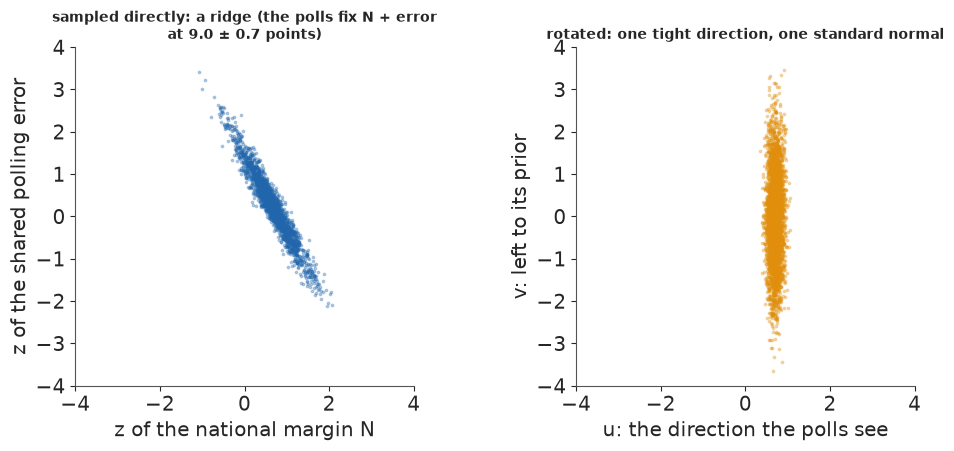

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
p26 = fit26["d"]["prior"]
zN = (naive26["N"] - p26["mu"]) / p26["sd"]
zB = naive26["bias"] / fit26["d"]["perr"]["shared"]
s_ = fit26["N"] + fit26["bias"]
axes[0].scatter(zN, zB, s=3, color=D_C, alpha=0.3)
axes[0].set_xlabel("z of the national margin N")
axes[0].set_ylabel("z of the shared polling error")
axes[0].set_title(f"sampled directly: a ridge (the polls fix N + error\nat {np.median(s_):.1f} ± {s_.std():.1f} points)",
                  fontsize=10)
zr = az.extract(fit26["idata"], var_names=["z_rot"]).values
axes[1].scatter(zr[0], zr[1], s=3, color=GOLD, alpha=0.3)
axes[1].set_xlabel("u: the direction the polls see")
axes[1].set_ylabel("v: left to its prior")
axes[1].set_title("rotated: one tight direction, one standard normal", fontsize=10)
for ax in axes:
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal");

### 3.4 Does the model reproduce the polls?

A posterior predictive check in poll space asks whether the polls look like draws from the fitted model.
It cannot see the shared error, because a shift of all polls together is absorbed by $b$: only results
can test that (E40's lesson), which is what the backtests are for.

aggregator snapshots: 90% predictive interval covers 99.2% of 123
race polls: 90% predictive interval covers 97.0% of 534


/tmp/ipykernel_2528106/642646872.py:17: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


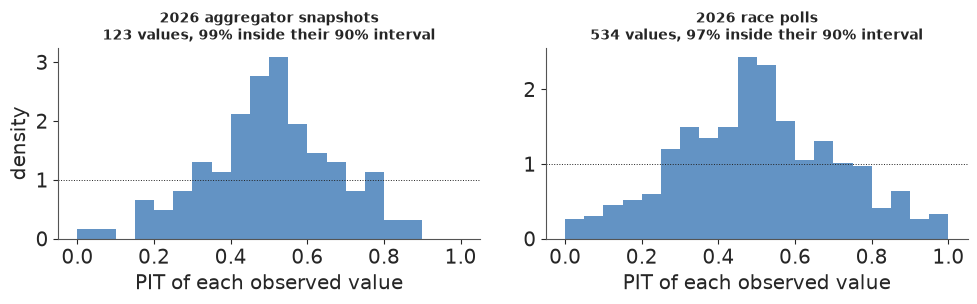

In [12]:
with build_model(fit26["d"]):
    ppc26 = pm.sample_posterior_predictive(fit26["idata"].isel(draw=slice(None, None, 4)), var_names=["gen", "racepoll"],
                                           random_seed=RANDOM_SEED, progressbar=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (v, obs, lab) in zip(axes, (("gen", fit26["d"]["gp"].two, "aggregator snapshots"),
                                    ("racepoll", fit26["d"]["rp"].two, "race polls"))):
    rep = ppc26.posterior_predictive[v].stack(s=("chain", "draw")).transpose("s", ...).values
    pit = (rep < obs.to_numpy()).mean(0)
    ax.hist(pit, bins=20, range=(0, 1), color=D_C, alpha=0.7, density=True)
    ax.axhline(1, color=INK, lw=0.7, ls=":")
    lo, hi = np.quantile(rep, [0.05, 0.95], 0)
    cov = np.mean((obs.to_numpy() >= lo) & (obs.to_numpy() <= hi))
    ax.set_title(f"2026 {lab}\n{len(obs)} values, {cov:.0%} inside their 90% interval", fontsize=10)
    ax.set_xlabel("PIT of each observed value")
    print(f"{lab}: 90% predictive interval covers {cov:.1%} of {len(obs)}")
axes[0].set_ylabel("density")
fig.tight_layout()
del ppc26;

Almost all 2026 aggregator snapshots (99%) and 97% of race polls fall inside their 90% predictive
intervals, and both PIT histograms are humped: the predictive spread is too wide in poll space. For the
snapshots that is by construction: each is given an sd of 1 point, but an average moves slowly from week
to week, and seven aggregators averaging largely the same polls count as seven measurements. That
matters little next to the shared error, but it is the price of having no individual national polls in
2026. For race polls the noise allowed is generous, which makes the forecast slightly cautious.

## 4 · The 2018 and 2022 backtests

A forecast's honesty is tested against results it did not see. 2018 and 2022 are the two midterms with
full FEC report files here, and in each we fit the model exactly as on the eve: polls entered by then,
money reported by then, coefficients from earlier cycles. Three variants of the same model measure what
each kind of information is worth:

* **full**: everything above;
* **aggregate only**: the national polls replaced by one 14-day rolling mean per week with an assumed sd
  of 1 point, which is the kind of national information 2026 has;
* **fundamentals only**: no polls at all, so $N$ comes from the midterm prior alone.

Six fits, each of 4 chains with nutpie's default 400 warm-up steps and 1,000 draws.

In [13]:
t0 = time.time()
FITS = {}
for c in (2018, 2022):
    for mode in ("full", "agg", "fund"):
        FITS[c, mode] = fit_cycle(c, mode)
TIMES["backtest fits"] = time.time() - t0
print(pd.DataFrame({f"{c} {m}": {k: f[k] for k in ("seconds", "divergences", "max r_hat", "worst", "min ESS")}
                    for (c, m), f in FITS.items()}).T.to_string())

             seconds divergences max r_hat   worst min ESS
2018 full  12.431343           0     1.006  b_race     790
2018 agg   11.968497           0     1.008   house     808
2018 fund   3.428967           1     1.009    z_st     409
2022 full  17.213932           0     1.008   s_int     709
2022 agg   14.460349           0     1.007  b_race     769
2022 fund   4.743245           0     1.026   gamma     255


All six fits have no or almost no divergences (one in the 2018 fundamentals-only fit) and an $\hat R$ of
at most 1.01, except the 2022 fundamentals-only fit, whose cycle intercept reaches 1.03: acceptable for
a baseline, not for a headline. A fourth forecast needs no sampler. **Polls only** is what a
poll-watcher would do: the average of a race's polls from the last three weeks where they exist, the
generic-poll average of the last 14 days plus the race's lean elsewhere, with the historical race-level
and shared polling errors and, for unpolled races, the residual spread of earlier cycles.

In [14]:
def polls_only(target, n=2000, seed=RANDOM_SEED):
    """A poll average where a race has polls, the generic average plus lean elsewhere; errors from history."""
    g = np.random.default_rng(seed)
    d = prepare(target)
    tm, P = d["tm"], polls[polls.cycle == target]
    elec = pd.Timestamp(ELEC[target])
    gen = P[(P.kind == "generic") & (P.end >= elec - pd.Timedelta(days=14))]
    gen_avg = float((100 * (2 * gen.dem / (gen.dem + gen.rep) - 1)).mean())
    rp = d["rp"]
    rp = rp[rp.week < 3].groupby("race").two.agg(["mean", "size"]).reindex(tm.race)
    resid = d["train"].assign(r=lambda t: t.m - t.cycle.map(MARGIN) - t.lean).groupby("office").r.std()
    shared = g.normal(0, d["perr"]["shared"], (n, 1))
    has = rp["size"].notna().to_numpy()
    base = np.where(has, rp["mean"].to_numpy(), gen_avg + tm.lean.to_numpy())
    sd = np.where(has, d["perr"]["race"], tm.office.map(resid).to_numpy())
    sim = base + shared + sd * g.standard_normal((n, len(tm)))
    return {"d": d, "sim": sim, "seats": seats(d, sim), "N": gen_avg + shared[:, 0], "gen_avg": gen_avg,
            "n_polled": int(has.sum())}


for c in (2018, 2022):
    FITS[c, "polls"] = polls_only(c)
    print(f"{c}: polls-only uses the 14-day generic average {FITS[c, 'polls']['gen_avg']:+.1f} and recent polls "
          f"in {FITS[c, 'polls']['n_polled']} races")

2018: polls-only uses the 14-day generic average +7.8 and recent polls in 121 races
2022: polls-only uses the 14-day generic average -0.7 and recent polls in 59 races


The polls-only generic average was D+7.8 on the eve of 2018 (the result was D+8.8) and R+0.7 in 2022
(the result was R+2.7): in 2022 the polls leaned Democratic by 2 points, that year's shared error.
Recent race polls exist in 121 races in 2018 and only 59 in 2022.

We score each forecast race by race with predictive draws of the margin: the **coverage** of its 50%,
80% and 90% intervals, the **PIT** (where the result falls in its predictive distribution), the **Brier
score** and the **log score** of the predicted winner, the median absolute error and the number of wrong
calls. And we compare seat intervals with the seats won.

In [15]:
def race_scores(sim, y):
    """Scores of predictive draws sim (draws x races) against outcomes y (D margin, points)."""
    S = sim.shape[0]
    pD = (sim > 0).mean(0)
    win = y > 0
    p_true = np.where(win, ((sim > 0).sum(0) + 0.5) / (S + 1), ((sim <= 0).sum(0) + 0.5) / (S + 1))
    out = {f"cover {int(100 * p)}%": float(np.mean((y >= np.quantile(sim, (1 - p) / 2, 0))
                                                     & (y <= np.quantile(sim, (1 + p) / 2, 0))))
           for p in (0.5, 0.8, 0.9)}
    out.update({"Brier": float(np.mean((pD - win) ** 2)), "log score": float(np.mean(np.log(p_true))),
                "MAE": float(np.mean(np.abs(np.median(sim, 0) - y))), "wrong calls": int(np.sum((pD > 0.5) != win))})
    return out, (sim < y).mean(0), pD


LABEL = {"full": "full model", "agg": "aggregate only", "fund": "fundamentals only", "polls": "polls only"}
score_rows, PIT, PD = [], {}, {}
for (c, mode), f in FITS.items():
    tm = f["d"]["tm"]
    y = tm.m.to_numpy()
    sc, PIT[c, mode], PD[c, mode] = race_scores(f["sim"], y)
    act = {off: int((f["d"]["tgt"][f["d"]["tgt"].office == off].winner == "D").sum()) for off in ("H", "S")}
    row = {"cycle": c, "model": LABEL[mode]}
    for off in ("H", "S"):
        q = np.quantile(f["seats"][off], [0.05, 0.5, 0.95])
        row[f"{off} seats"] = f"{q[1]:.0f} [{q[0]:.0f}, {q[2]:.0f}]"
        row[f"{off} actual"] = act[off]
    row["P(D House)"] = round(float((f["seats"]["H"] >= 218).mean()), 2)
    qn = np.quantile(f["N"], [0.05, 0.5, 0.95])
    row["national"] = f"{qn[1]:+.1f} [{qn[0]:+.1f}, {qn[2]:+.1f}]"
    row["actual N"] = round(MARGIN[c], 1)
    row.update({k: round(v, 3) if isinstance(v, float) else v for k, v in sc.items()})
    score_rows.append(row)
scores = pd.DataFrame(score_rows).sort_values(["cycle", "model"], key=lambda s: s.map(
    {"full model": 0, "aggregate only": 1, "polls only": 2, "fundamentals only": 3}) if s.name == "model" else s)
print(scores.drop(columns=["cover 50%", "cover 80%", "cover 90%", "Brier", "log score", "MAE", "wrong calls"]).to_string(index=False))
print()
print(scores[["cycle", "model", "cover 50%", "cover 80%", "cover 90%", "Brier", "log score", "MAE", "wrong calls"]].to_string(index=False))

 cycle             model        H seats  H actual     S seats  S actual  P(D House)           national  actual N
  2018        full model 222 [203, 244]       235 24 [20, 28]        24        0.65 +8.0 [+3.3, +12.6]       8.8
  2018    aggregate only 226 [207, 250]       235 25 [21, 28]        24        0.75 +6.4 [+1.5, +11.5]       8.8
  2018        polls only 236 [207, 265]       235 24 [20, 28]        24        0.84 +7.9 [+2.6, +12.8]       8.8
  2018 fundamentals only 225 [193, 274]       235 23 [17, 29]        24        0.63 +5.7 [-4.6, +16.8]       8.8
  2022        full model 204 [184, 222]       213 14 [11, 17]        15        0.12  -2.0 [-6.8, +3.0]      -2.7
  2022    aggregate only 201 [182, 220]       213 14 [10, 17]        15        0.08  -1.1 [-6.7, +4.2]      -2.7
  2022        polls only 208 [182, 232]       213 13 [10, 18]        15        0.27  -0.5 [-6.1, +4.6]      -2.7
  2022 fundamentals only 196 [156, 229]       213  12 [7, 17]        15        0.15 -4.5 [-14.9,

The full model's 90% seat and national intervals contain the result in both cycles, and its 90% race
intervals cover 93% and 92% of races, close to nominal. It gave the Democrats a 65% chance of the House
in 2018, which they won, and 12% in 2022, which they lost.

The comparison is the lesson. Without any poll the forecast is right on average but twice as uncertain
about seats and makes more wrong calls. Polls only gets the 2018 House almost exactly, but its intervals
are too wide and its log score is the worst of the four in 2022: where a district has no poll, lean
alone is a blunt instrument. Aggregate only loses nothing on races, but its national median was more
than 2 points short in 2018. Two cycles are two draws of the shared polling error, so differences of a
few hundredths in Brier score are noise; the gaps to the fundamentals-only forecast are not.

2018: 26 wrong calls, 26 in polled races, 21 won by a Democrat forecast to lose
2022: 21 wrong calls, 15 in polled races, 15 won by a Democrat forecast to lose


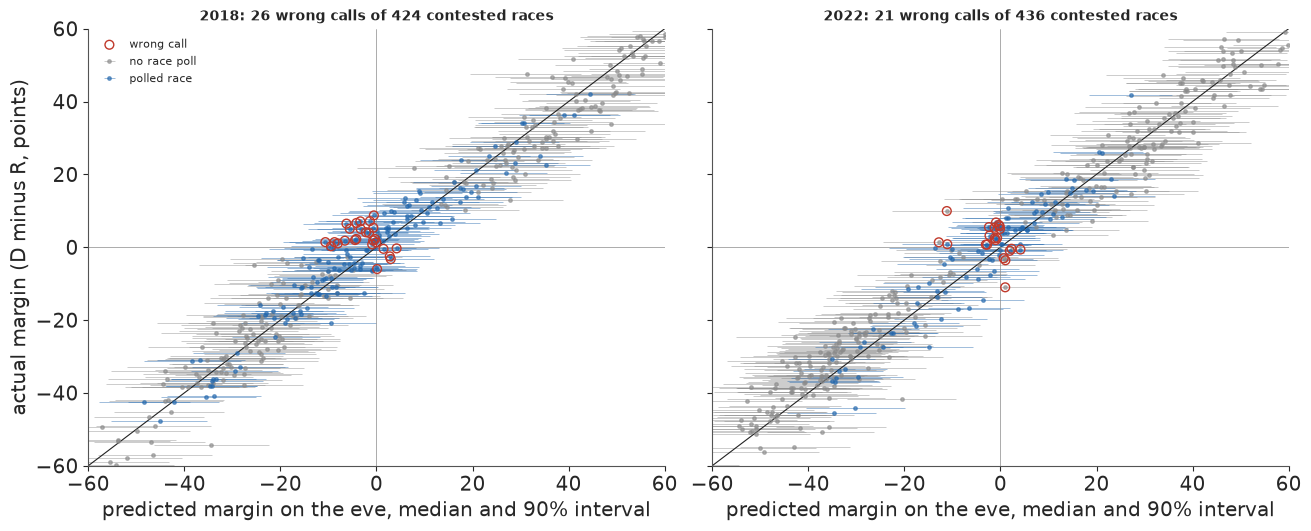

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, c in zip(axes, (2018, 2022)):
    f = FITS[c, "full"]
    tm = f["d"]["tm"]
    y = tm.m.to_numpy()
    med = np.median(f["sim"], 0)
    lo, hi = np.quantile(f["sim"], [0.05, 0.95], 0)
    pol = tm.race.isin(f["d"]["polled"]).to_numpy()
    for sel, col, lab in ((~pol, MUTED, "no race poll"), (pol, D_C, "polled race")):
        ax.errorbar(med[sel], y[sel], xerr=[med[sel] - lo[sel], hi[sel] - med[sel]], fmt="o", ms=2.5,
                    color=col, elinewidth=0.5, alpha=0.6, label=lab)
    wrong = (med > 0) != (y > 0)
    ax.scatter(med[wrong], y[wrong], s=40, facecolor="none", edgecolor=R_C, lw=1, label="wrong call", zorder=5)
    print(f"{c}: {int(wrong.sum())} wrong calls, {int((wrong & pol).sum())} in polled races, "
          f"{int((wrong & (y > 0)).sum())} won by a Democrat forecast to lose")
    ax.plot([-80, 80], [-80, 80], color=INK, lw=0.8)
    ax.axhline(0, color=MUTED, lw=0.5)
    ax.axvline(0, color=MUTED, lw=0.5)
    ax.set_xlim(-60, 60)
    ax.set_ylim(-60, 60)
    ax.set_xlabel("predicted margin on the eve, median and 90% interval")
    ax.set_title(f"{c}: {int(wrong.sum())} wrong calls of {len(y)} contested races", fontsize=10)
axes[0].set_ylabel("actual margin (D minus R, points)")
axes[0].legend(fontsize=8, loc="upper left");

Most wrong calls sit near zero on both axes and in polled races, because close races get polled. In
both years most of them (21 of 26, and 15 of 21) are Democrats who won races the forecast expected them
to lose: a shared error, seen race by race.

full model reliability (mean forecast, share won, races): [(np.float64(0.0), np.float64(0.01), 364), (np.float64(0.1), np.float64(0.17), 41), (np.float64(0.27), np.float64(0.36), 22), (np.float64(0.44), np.float64(0.63), 27), (np.float64(0.57), np.float64(0.7), 23), (np.float64(0.73), np.float64(0.82), 22), (np.float64(0.89), np.float64(1.0), 28), (np.float64(1.0), np.float64(1.0), 333)]
polls only reliability (mean forecast, share won, races): [(np.float64(0.01), np.float64(0.01), 277), (np.float64(0.11), np.float64(0.05), 81), (np.float64(0.26), np.float64(0.16), 43), (np.float64(0.44), np.float64(0.41), 37), (np.float64(0.57), np.float64(0.74), 34), (np.float64(0.73), np.float64(0.83), 41), (np.float64(0.9), np.float64(0.96), 69), (np.float64(0.99), np.float64(1.0), 278)]


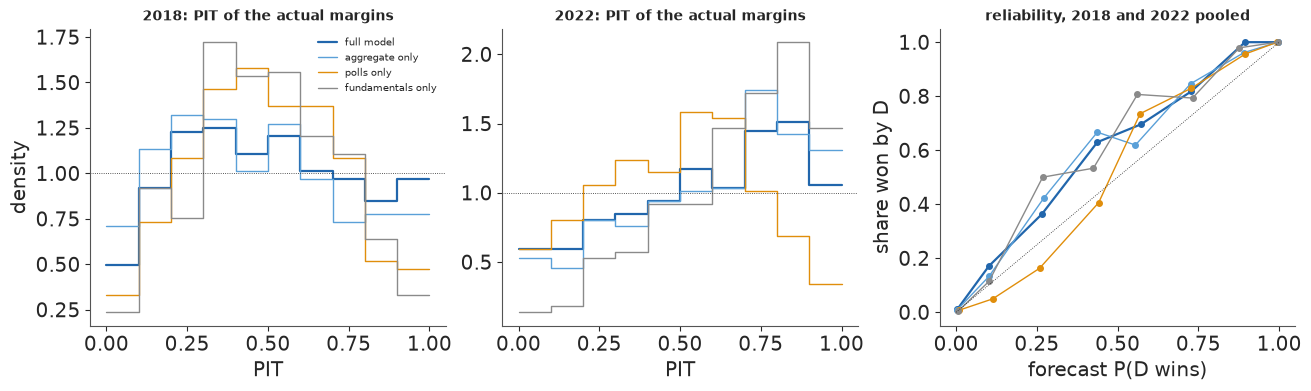

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
modes = ("full", "agg", "polls", "fund")
mcol = {"full": D_C, "agg": "#5aa0d8", "polls": GOLD, "fund": MUTED}
for ax, c in zip(axes[:2], (2018, 2022)):
    for k, mode in enumerate(modes):
        h, e = np.histogram(PIT[c, mode], bins=10, range=(0, 1))
        ax.step(e, np.r_[h, h[-1]] / h.sum() * 10, where="post", color=mcol[mode], lw=1.6 if mode == "full" else 1,
                label=LABEL[mode])
    ax.axhline(1, color=INK, lw=0.6, ls=":")
    ax.set_title(f"{c}: PIT of the actual margins", fontsize=10)
    ax.set_xlabel("PIT")
axes[0].set_ylabel("density")
axes[0].legend(fontsize=7)
ax = axes[2]
bins = np.array([0, 0.05, 0.2, 0.35, 0.5, 0.65, 0.8, 0.95, 1.0001])
for mode in modes:
    p = np.r_[PD[2018, mode], PD[2022, mode]]
    w = np.r_[FITS[2018, mode]["d"]["tm"].m > 0, FITS[2022, mode]["d"]["tm"].m > 0]
    b = np.digitize(p, bins) - 1
    xs = [p[b == i].mean() for i in range(len(bins) - 1) if (b == i).sum() >= 5]
    ys = [w[b == i].mean() for i in range(len(bins) - 1) if (b == i).sum() >= 5]
    ax.plot(xs, ys, "o-", color=mcol[mode], ms=4, lw=1.6 if mode == "full" else 1)
    if mode in ("full", "polls"):
        print(LABEL[mode], "reliability (mean forecast, share won, races):",
              [(round(a_, 2), round(b_, 2), int((b == i).sum())) for i, a_, b_ in
               zip([i for i in range(len(bins) - 1) if (b == i).sum() >= 5], xs, ys)])
ax.plot([0, 1], [0, 1], color=INK, lw=0.6, ls=":")
ax.set_xlabel("forecast P(D wins)")
ax.set_ylabel("share won by D")
ax.set_title("reliability, 2018 and 2022 pooled", fontsize=10);

In 2018 the full model's PIT is nearly flat; in 2022 it rises to the right, because results came in more
Democratic than forecast across many races. The fundamentals-only PIT is humped: its intervals were
wider than needed. In the reliability diagram, which pools both cycles, Democrats won 36% of the 22 races
the full model gave them about a 27% chance and 63% of the 27 given about 44%: across the middle they
won more often than forecast, the same lean as the PITs.

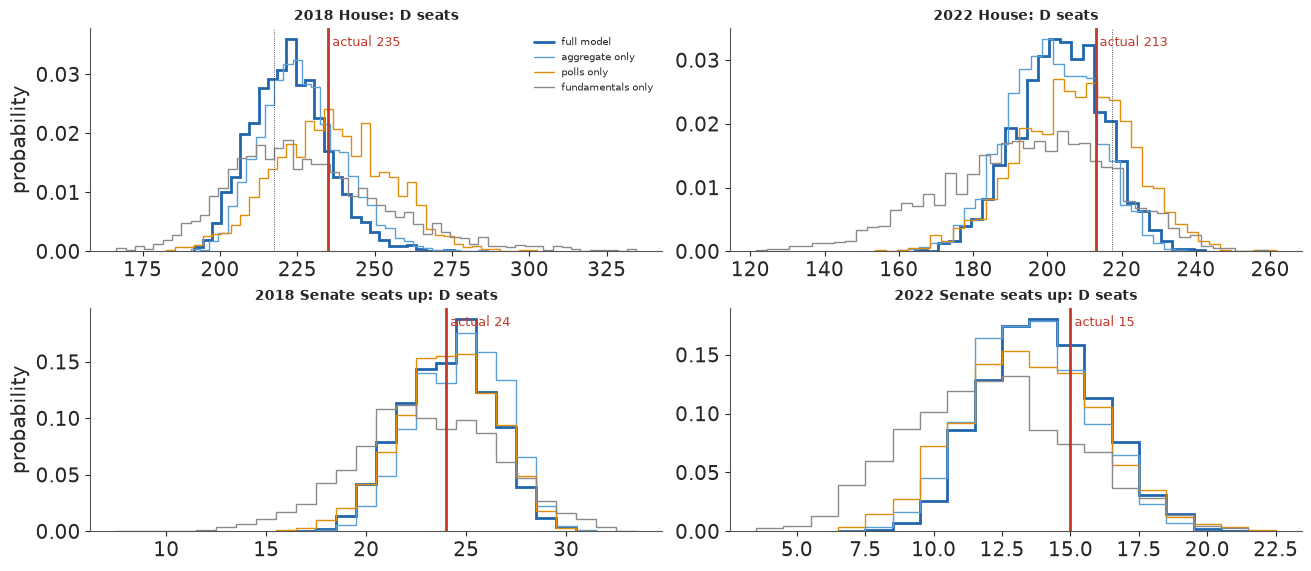

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 5.6))
for j, c in enumerate((2018, 2022)):
    for i, off in enumerate(("H", "S")):
        ax = axes[i, j]
        act = int((FITS[c, "full"]["d"]["tgt"].query("office == @off").winner == "D").sum())
        for mode in modes:
            s = FITS[c, mode]["seats"][off]
            w_ = 3 if off == "H" else 1                       # House seats binned in threes for display
            e = np.arange(s.min() - 0.5, s.max() + w_, w_)
            v, _ = np.histogram(s, e)
            ax.stairs(v / len(s) / w_, e, color=mcol[mode], lw=2 if mode == "full" else 1, label=LABEL[mode],
                      fill=False)
        ax.axvline(act, color=R_C, lw=2)
        ax.text(act, ax.get_ylim()[1] * 0.92, f" actual {act}", color=R_C, fontsize=9)
        if off == "H":
            ax.axvline(217.5, color=INK, lw=0.6, ls=":")
        ax.set_title(f"{c} {'House' if off == 'H' else 'Senate seats up'}: D seats", fontsize=10)
axes[0, 0].legend(fontsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel("probability");

In both years the full model's House distribution sits a few seats below the result, with the result
inside its central region; the fundamentals-only distributions are far wider.

train                      2016            2016-20            2016-22
office x                                                             
H      inc     5.6 [4.56, 6.71]   3.6 [3.04, 4.14]  3.28 [2.84, 3.75]
       lean   8.04 [7.73, 8.35]  8.34 [8.17, 8.51]  8.52 [8.37, 8.66]
       money  2.92 [2.47, 3.36]  2.72 [2.48, 2.96]  2.41 [2.21, 2.61]
S      inc    2.48 [0.21, 4.76]   2.87 [1.45, 4.4]   2.58 [1.18, 3.9]
       lean   7.01 [5.79, 8.27]   7.84 [7.1, 8.62]  7.85 [7.16, 8.54]
       money  4.56 [3.47, 5.64]   2.8 [2.12, 3.48]  2.58 [2.01, 3.17]


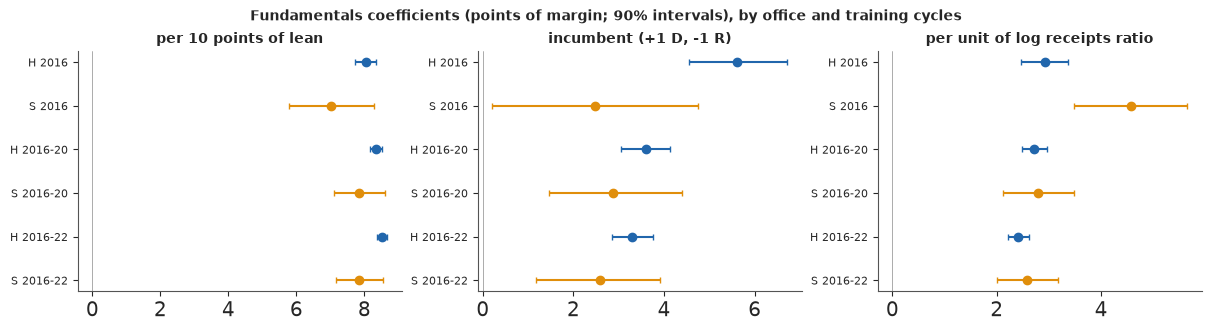

In [19]:
def coef_frame(f, label):
    b = f["beta"]
    rows = []
    for i, off in enumerate(("H", "S")):
        for j, x in enumerate(("lean", "inc", "money")):
            q = np.quantile(b[:, i, j], [0.05, 0.5, 0.95])
            rows.append({"train": label, "office": off, "x": x, "lo": q[0], "med": q[1], "hi": q[2]})
    return rows


cf = pd.DataFrame(coef_frame(FITS[2018, "full"], "2016") + coef_frame(FITS[2022, "full"], "2016-20")
                  + coef_frame(fit26, "2016-22"))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
xlab = {"lean": "per 10 points of lean", "inc": "incumbent (+1 D, -1 R)", "money": "per unit of log receipts ratio"}
for ax, x in zip(axes, ("lean", "inc", "money")):
    s = cf[cf.x == x].reset_index(drop=True)
    for k, r in s.iterrows():
        col = D_C if r.office == "H" else GOLD
        ax.errorbar(r.med, k, xerr=[[r.med - r.lo], [r.hi - r.med]], fmt="o", color=col, capsize=2)
    ax.set_yticks(range(len(s)), [f"{r.office} {r.train}" for _, r in s.iterrows()], fontsize=8)
    ax.set_title(xlab[x], fontsize=10)
    ax.axvline(0, color=MUTED, lw=0.5)
axes[0].invert_yaxis()
for ax in axes[1:]:
    ax.invert_yaxis()
fig.suptitle("Fundamentals coefficients (points of margin; 90% intervals), by office and training cycles", fontsize=10)
print(cf.assign(est=lambda t: t.med.round(2).astype(str) + " [" + t.lo.round(2).astype(str) + ", "
               + t.hi.round(2).astype(str) + "]").pivot(index=["office", "x"], columns="train", values="est").to_string());

The fundamentals are stable across training sets. Ten points of lean move a House margin by about 8
points; incumbency is worth about 3-4 points in the House and 2.5 in the Senate. The **money**
coefficient is about 2.4-2.9 points of House margin per unit of the log receipts ratio: a Democrat who
has raised $e \approx 2.7$ times as much leans 2-3 points further than lean and incumbency predict. That
is a forecast signal, not an effect of spending: donors give to candidates they expect to do well.

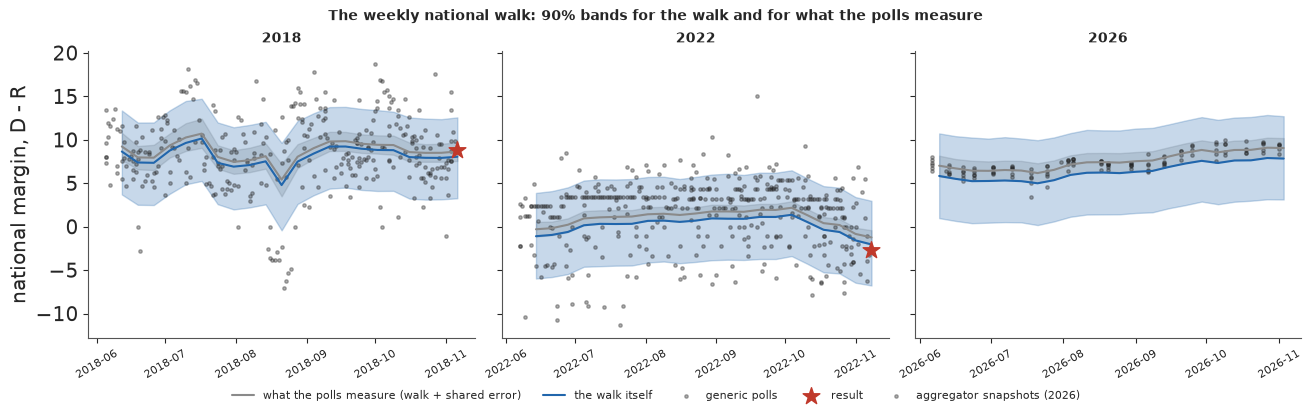

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (c, f) in zip(axes, ((2018, FITS[2018, "full"]), (2022, FITS[2022, "full"]), (2026, fit26))):
    elec = pd.Timestamp(ELEC[c])
    wk = elec - pd.to_timedelta(7 * np.arange(22), "D")
    seen = f["walk"] + f["bias"][:, None]
    for arr, col, lab in ((seen, MUTED, "what the polls measure (walk + shared error)"), (f["walk"], D_C, "the walk itself")):
        lo, mid, hi = np.quantile(arr, [0.05, 0.5, 0.95], 0)
        ax.fill_between(wk, lo, hi, color=col, alpha=0.25)
        ax.plot(wk, mid, color=col, lw=1.5, label=lab)
    gp = f["d"]["gp"]
    P = polls[(polls.cycle == c) & (polls.kind == ("generic_avg" if c == 2026 else "generic"))]
    P = P[P.end >= elec - pd.Timedelta(days=7 * 22)]
    ax.scatter(P.end, 100 * (2 * P.dem / (P.dem + P.rep) - 1), s=6, color=INK, alpha=0.35,
               label="aggregator snapshots" if c == 2026 else "generic polls")
    if c < 2026:
        ax.scatter([elec], [MARGIN[c]], marker="*", s=160, color=R_C, zorder=6, label="result")
    ax.set_title(f"{c}", fontsize=10)
    ax.tick_params(axis="x", labelsize=8, rotation=30)
axes[0].set_ylabel("national margin, D - R")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_ + axes[2].get_legend_handles_labels()[0][-1:], l_ + ["aggregator snapshots (2026)"], fontsize=8,
           loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("The weekly national walk: 90% bands for the walk and for what the polls measure", fontsize=10);

What the polls measure (walk plus shared error) is a narrow band; the walk itself is wider, because the
shared error is unknown. In 2022 the result fell below what the polls measured but inside the walk's
band: the model had allowed for the polls leaning Democratic. The 2026 band is smooth because its inputs
are averages, and ends near D+8.

## 5 · Money and votes

Does money win elections? The forecast coefficient above is not the answer. The naive way to ask is to
regress an incumbent's vote share on what each candidate spent. Jacobson (1978, 1990) did this and found
a paradox: the more an incumbent spends, the worse the incumbent does. We redo it on the 663 contested
House races with an incumbent in 2018 and 2022, with spending as cycle totals from the FEC (log10, so a
coefficient is per tenfold).

In [21]:
x = R[R.cycle.isin([2018, 2022]) & (R.office == "H") & R.modelled & (R.d_inc | R.r_inc)].copy()
x["inc_share"] = 100 * np.where(x.d_inc, x.dem2, 1 - x.dem2)
dsp, rsp = x.d_disb_final.fillna(0).to_numpy(), x.r_disb_final.fillna(0).to_numpy()
x["inc_sp"] = np.log10(np.where(x.d_inc, dsp, rsp).clip(1e4))     # $10k floor: some challengers spend ~nothing
x["ch_sp"] = np.log10(np.where(x.d_inc, rsp, dsp).clip(1e4))
x["lean_inc"] = np.where(x.d_inc, x.lean, -x.lean)


def ols(cols, y):
    A = np.c_[np.ones(len(y)), cols]
    b, *_ = np.linalg.lstsq(A, y, rcond=None)
    res = y - A @ b
    se = np.sqrt(np.diag(np.linalg.inv(A.T @ A)) * res.var(ddof=A.shape[1]))
    return b, se


b0, se0 = ols(np.c_[x.inc_sp, x.ch_sp], x.inc_share.to_numpy())
b1, se1 = ols(np.c_[x.inc_sp, x.ch_sp, x.lean_inc, x.cycle == 2022], x.inc_share.to_numpy())
print(f"{len(x)} contested House races with an incumbent, 2018 and 2022 (incumbent's two-party share, points)")
print(f"naive:            incumbent spending {b0[1]:+.1f} ± {se0[1]:.1f} per tenfold, challenger {b0[2]:+.1f} ± {se0[2]:.1f}")
print(f"+ lean and cycle: incumbent spending {b1[1]:+.1f} ± {se1[1]:.1f} per tenfold, challenger {b1[2]:+.1f} ± {se1[2]:.1f}, "
      f"lean {b1[3]:+.2f} per point")
print(f"correlation of log incumbent spending with |incumbent share - 50|: "
      f"{np.corrcoef(x.inc_sp, np.abs(x.inc_share - 50))[0, 1]:+.2f}")

663 contested House races with an incumbent, 2018 and 2022 (incumbent's two-party share, points)
naive:            incumbent spending -0.7 ± 0.7 per tenfold, challenger -7.6 ± 0.3
+ lean and cycle: incumbent spending +1.0 ± 0.4 per tenfold, challenger -3.6 ± 0.2, lean +0.37 per point
correlation of log incumbent spending with |incumbent share - 50|: -0.30


Failure 2, a regression that answers the wrong question. Naively, a tenfold increase in the incumbent's
spending goes with -0.7 points of share, and in the challenger's with -7.6. Adding the district's lean
and a cycle term turns the incumbent's coefficient positive (+1.0) and halves the challenger's (-3.6),
and the lean coefficient (+0.37 points of share per point of lean) shows how much of the original
pattern was district. The reason is reverse causation: incumbents spend when they are in danger. The
correlation of log incumbent spending with the incumbent's distance from 50% is -0.30. Adding lean does
not solve the problem, because danger has causes the data do not record (a scandal, a strong challenger,
a bad local economy), and those raise both spending and the chance of losing.

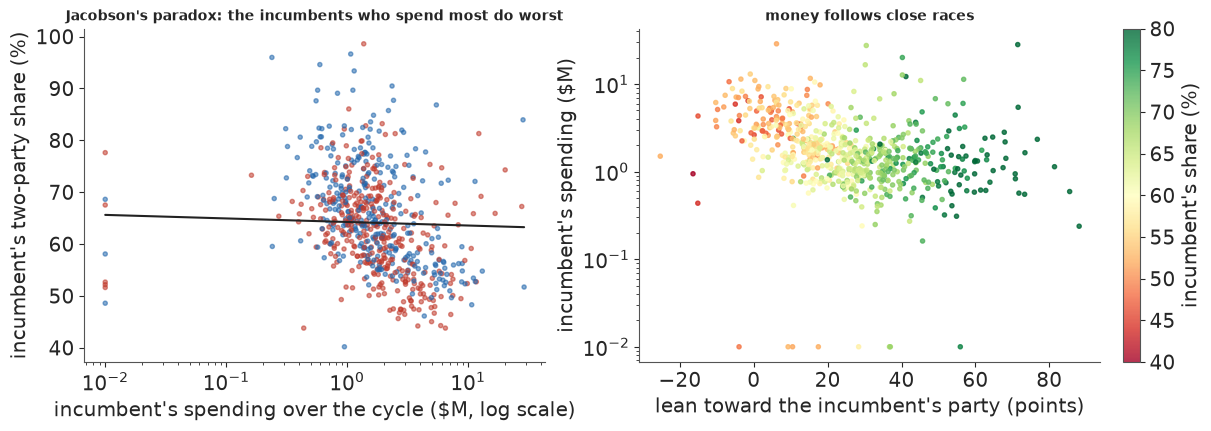

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
col = np.where(x.d_inc, D_C, R_C)
ax.scatter(10 ** x.inc_sp / 1e6, x.inc_share, s=9, c=col, alpha=0.55)
xs = np.linspace(x.inc_sp.min(), x.inc_sp.max(), 50)
ax.plot(10 ** xs / 1e6, b0[0] + b0[1] * xs + b0[2] * x.ch_sp.mean(), color=INK, lw=1.5)
ax.set_xscale("log")
ax.set_xlabel("incumbent's spending over the cycle ($M, log scale)")
ax.set_ylabel("incumbent's two-party share (%)")
ax.set_title("Jacobson's paradox: the incumbents who spend most do worst", fontsize=10)
ax = axes[1]
sc = ax.scatter(x.lean_inc, 10 ** x.inc_sp / 1e6, s=9, c=x.inc_share, cmap="RdYlGn", vmin=40, vmax=80, alpha=0.8)
ax.set_yscale("log")
ax.set_xlabel("lean toward the incumbent's party (points)")
ax.set_ylabel("incumbent's spending ($M)")
ax.set_title("money follows close races", fontsize=10)
fig.colorbar(sc, ax=ax, label="incumbent's share (%)");

In the left panel, the most expensive incumbents are the ones with the lowest shares; in the right,
money piles up where the lean is small, and spending falls as the seat gets safer. Money follows close
races.

### 5.1 Rematches: the same two candidates, twice

Levitt (1994) used a natural design: the same two candidates meeting in the same district in two
elections. Whatever is fixed about the pair and the place, the candidates' quality, their name
recognition, the district's habits, cancels in the change from one meeting to the next. Write the change
in the Democratic share (in points) between meetings $\Delta v_j$ against the changes in log spending of
each side, with a national swing per cycle $a_c$ (a wave year moves every rematch) and slopes that vary
by cycle around a common mean:

$$
\Delta v_j \sim t_\nu\big(a_{c(j)} + \beta^D_{c(j)} \Delta \log D_j + \beta^R_{c(j)} \Delta \log R_j,\ \sigma\big),
\qquad \beta^{D}_{c} = \mu_D + \tau_D z^D_c,\ \ \beta^{R}_{c} = \mu_R + \tau_R z^R_c.
$$

The Student-t allows for a rematch where something odd happened between meetings. The builder found 232
usable rematches with spending on both sides in both meetings, in 2006-2020, leaving out cycles across a
redistricting (2012, 2022) and court-ordered redraws. A pilot with centred slopes gave 33 divergences;
with seven cycles and few rematches per cycle the slopes are weakly identified, which is where the
non-centred form above samples cleanly.

In [23]:
rm = rematch[(rematch.d_disb > 0) & (rematch.r_disb > 0) & (rematch.d_disb_prev > 0) & (rematch.r_disb_prev > 0)].copy()
rm["dv"] = 100 * (rm.dem2 - rm.dem2_prev)
rm["dd"] = np.log(rm.d_disb / rm.d_disb_prev)
rm["dr"] = np.log(rm.r_disb / rm.r_disb_prev)
rcyc = sorted(rm.cycle.unique())
ci = rm.cycle.map({c: i for i, c in enumerate(rcyc)}).to_numpy()
print(f"{len(rm)} rematches with spending on both sides in both meetings:", rm.groupby("cycle").size().to_dict())
bf, sef = ols(np.c_[rm.dd, rm.dr], rm.dv.to_numpy())
print(f"first differences, OLS: D spending {bf[1]:+.2f} ± {sef[1]:.2f}, R spending {bf[2]:+.2f} ± {sef[2]:.2f} "
      "points of D share per e-fold")

with pm.Model(coords={"cycle": rcyc, "side": ["D", "R"]}) as m_rm:
    a = pm.Normal("swing", 0, 5, dims="cycle")
    b_mu = pm.Normal("b_mu", 0, 2, dims="side")
    tau = pm.HalfNormal("tau", 1.0, dims="side")
    z = pm.Normal("z", 0, 1, dims=("cycle", "side"))
    b = pm.Deterministic("b", b_mu + tau * z, dims=("cycle", "side"))
    sd = pm.HalfNormal("sd", 5)
    nu = pm.Gamma("nu", 2, 0.1)
    pm.StudentT("dv", nu=nu, mu=a[ci] + b[ci, 0] * rm.dd.to_numpy() + b[ci, 1] * rm.dr.to_numpy(), sigma=sd,
                observed=rm.dv.to_numpy())
    t0 = time.time()
    idata_rm = pm.sample(random_seed=RANDOM_SEED, progressbar=False, target_accept=0.95)
TIMES["rematch fit"] = time.time() - t0
print(diagnostics(idata_rm))
print(az.summary(idata_rm, var_names=["b_mu", "tau", "sd", "nu"], round_to=2).to_string())
bmu = az.extract(idata_rm, var_names=["b_mu"]).values
print(f"P(D slope > 0) = {(bmu[0] > 0).mean():.2f}, P(R slope < 0) = {(bmu[1] < 0).mean():.2f}; "
      f"doubling D spending: {np.log(2) * np.median(bmu[0]):+.2f} points "
      f"[{np.log(2) * np.quantile(bmu[0], 0.05):+.2f}, {np.log(2) * np.quantile(bmu[0], 0.95):+.2f}]")

232 rematches with spending on both sides in both meetings: {2006: 35, 2008: 38, 2010: 36, 2014: 24, 2016: 36, 2018: 21, 2020: 42}
first differences, OLS: D spending +1.82 ± 0.39, R spending -0.64 ± 0.33 points of D share per e-fold


{'divergences': 0, 'max r_hat': 1.006, 'worst': 'tau', 'min ESS': 857, 'tuning': 400}
          mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
b_mu[D]   0.95   0.40      0.32      1.57   2039.04   2223.99   1.00       0.01     0.01
b_mu[R]  -0.19   0.34     -0.69      0.37   2078.12   2228.90   1.00       0.01     0.01
tau[D]    0.66   0.39      0.11      1.34    857.59    717.81   1.00       0.01     0.01
tau[R]    0.49   0.36      0.05      1.14    889.35    891.81   1.01       0.01     0.01
sd        2.68   0.21      2.32      3.02   2312.43   2288.86   1.00       0.00     0.00
nu       14.76  10.71      4.75     35.01   2183.32   2533.00   1.00       0.22     0.28
P(D slope > 0) = 0.98, P(R slope < 0) = 0.75; doubling D spending: +0.67 points [+0.21, +1.10]


The simple first-difference regression, without cycle swings, gives +1.8 points per e-fold of Democratic
spending. Some of that is plausibly national tides: in wave years (2006, 2018) the Democrats could both
raise more and win more everywhere, and a swing per cycle absorbs that. With it, the hierarchical model
gives a common slope of **+0.95 points of Democratic share per e-fold of Democratic spending** (89%
interval 0.32 to 1.57) and -0.19 for Republican spending (-0.69 to 0.37). Doubling the Democrat's
spending in a rematch is worth about +0.7 points of share, with a 90% interval of 0.2 to 1.1: real, and
small. The sampler had no divergences.

The bounds are worth stating. Candidate quality can still change between meetings, and a challenger who
raises more the second time may be one whose prospects improved for other reasons, which would bias the
slope **up**. Rematches are a selected sample, and spending is measured as cycle totals including
primaries. Levitt read his estimates as an upper bound on a small effect; ours points the same way. The asymmetry between the
parties should not be over-read: in size, the two slopes' intervals overlap between about 0.3 and 0.7.

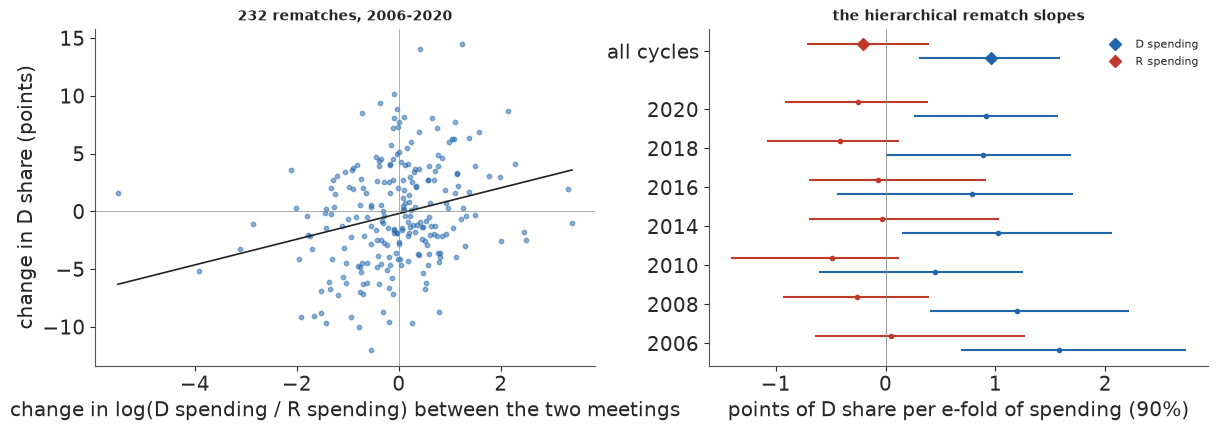

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ratio = rm.dd - rm.dr
ax.scatter(ratio, rm.dv, s=10, color=D_C, alpha=0.5)
k_ = np.polyfit(ratio, rm.dv, 1)
xs = np.linspace(ratio.min(), ratio.max(), 20)
ax.plot(xs, np.polyval(k_, xs), color=INK, lw=1.2)
ax.axhline(0, color=MUTED, lw=0.5)
ax.axvline(0, color=MUTED, lw=0.5)
ax.set_xlabel("change in log(D spending / R spending) between the two meetings")
ax.set_ylabel("change in D share (points)")
ax.set_title(f"{len(rm)} rematches, 2006-2020", fontsize=10)
ax = axes[1]
bb = idata_rm.posterior["b"]
for s_i, (side, col) in enumerate((("D", D_C), ("R", R_C))):
    for k, c in enumerate(rcyc):
        v = bb.sel(side=side, cycle=c).values.ravel()
        q = np.quantile(v, [0.05, 0.5, 0.95])
        ax.errorbar(q[1], k + 0.18 * (s_i * 2 - 1), xerr=[[q[1] - q[0]], [q[2] - q[1]]], fmt="o", color=col, ms=3)
    q = np.quantile(bmu[s_i], [0.05, 0.5, 0.95])
    ax.errorbar(q[1], len(rcyc) + 0.5 + 0.18 * (s_i * 2 - 1), xerr=[[q[1] - q[0]], [q[2] - q[1]]], fmt="D", color=col,
                ms=6, label=f"{side} spending")
ax.set_yticks(list(range(len(rcyc))) + [len(rcyc) + 0.5], [str(c) for c in rcyc] + ["all cycles"])
ax.axvline(0, color=MUTED, lw=0.6)
ax.set_xlabel("points of D share per e-fold of spending (90%)")
ax.legend(fontsize=8)
ax.set_title("the hierarchical rematch slopes", fontsize=10);

In the left panel the rematches spread widely around a gentle slope, and in the right the per-cycle
slopes overlap each other and the common mean: no cycle stands out, so the pooling across cycles is
doing what it should.

## 6 · Nowcasting campaign spending

On election day nobody knows how much the campaigns spent, because of the reporting calendar. A
candidate's committee files a **pre-general report (12G)** covering the period to 14 October 2026, and
a **post-general report (30G)** covering from there to 23 November, due on 3 December. The busiest five
weeks are reported a month after the election. Outside groups making **independent expenditures** (IE)
file 24- or 48-hour reports, so outside money is visible almost at once. The 48-hour notices of large
contributions are receipts, not spending, and are in no bulk file; they are not used.

The target is defined so that it can be checked: the disbursements of each Democratic and Republican
nominee's committees through the end of the 30G period, plus general-election IE dated through
election day. A backtest truncates the 2018 and 2022 filings at what the FEC had **received** by each
eve, so nothing from after the eve leaks in, and compares the nowcast with what was eventually filed.

In [25]:
def spend_window(cycle):
    """Nominee reports covering the cycle up to the end of the post-general period (post-election runoffs out)."""
    r = reports[reports.cycle == cycle]
    runoff_after = r.rpt.isin(["12R", "30R"]) & (r.cvg_end > pd.Timestamp(EVE[cycle]))
    return r[~runoff_after & (r.cvg_end <= pd.Timestamp(END_30G[cycle]))]


def cumulative(r, elec, days=np.arange(-730, 21)):
    """Cumulative disbursements by day relative to election day, each report spread evenly over its period."""
    s = (r.cvg_start - elec).dt.days.clip(days[0]).to_numpy()
    e = (r.cvg_end - elec).dt.days.to_numpy()
    rate = r.disb.to_numpy() / np.maximum(e - s + 1, 1)
    out = np.zeros(len(days))
    for si, ei, ra in zip(s, e, rate):
        out += ra * np.clip(days - si + 1, 0, ei - si + 1)
    return days, out


SPEND = {}
for c in (2018, 2022, 2026):
    w = spend_window(c)
    eve = pd.Timestamp(EVE[c])
    SPEND[c] = {"final": w.disb.sum(), "known": w[w.receipt <= eve].disb.sum(),
                "n_cands": w.cand_id.nunique(), "late_30G": w[w.rpt == "30G"].disb.sum()}
    f = ie[(ie.cycle == c) & (ie.version == "final")]
    SPEND[c]["ie_final"] = f.amt.sum()
    SPEND[c]["ie_known"] = f.amt[f.first_receipt <= eve].sum()
sp = pd.DataFrame(SPEND).T
sp_show = (sp[["n_cands", "known", "final", "late_30G", "ie_known", "ie_final"]]
           .assign(**{c: lambda t, c=c: (t[c] / 1e6).round(0) for c in ("known", "final", "late_30G", "ie_known", "ie_final")}))
sp_show["share of nominee spending unseen on the eve"] = (1 - sp.known / sp.final).round(3)
sp_show["share of IE unseen"] = (1 - sp.ie_known / sp.ie_final).round(4)
print("$M; 2026 'final' is what has been filed so far (nothing after the eve)")
print(sp_show.to_string())

$M; 2026 'final' is what has been filed so far (nothing after the eve)
      n_cands   known   final  late_30G  ie_known  ie_final  share of nominee spending unseen on the eve  share of IE unseen
2018    843.0  1679.0  2123.0     443.0    1045.0    1049.0                                        0.209               0.004
2022    846.0  2316.0  2751.0     435.0    1610.0    1623.0                                        0.158               0.008
2026    876.0  2408.0  2408.0       0.0    3171.0    3171.0                                        0.000               0.000


On the eve of 2018, the reports already filed held \$1.68B of the nominees' spending; a month later the
total through the 30G was \$2.12B. In 2022: \$2.32B on the eve and \$2.75B in the end. About a fifth of
nominee spending (21% and 16%) was unseen on the eve, and nearly all of it (\$443M and \$435M) arrived in
one report, the 30G. Outside money is the opposite: 99.6% (2018) and 99.2% (2022) of the eventual
general-election IE dollars had been received by the eve. 2026 has \$2.41B of nominee spending and \$3.17B
of outside spending on file, twice the outside money of 2022.

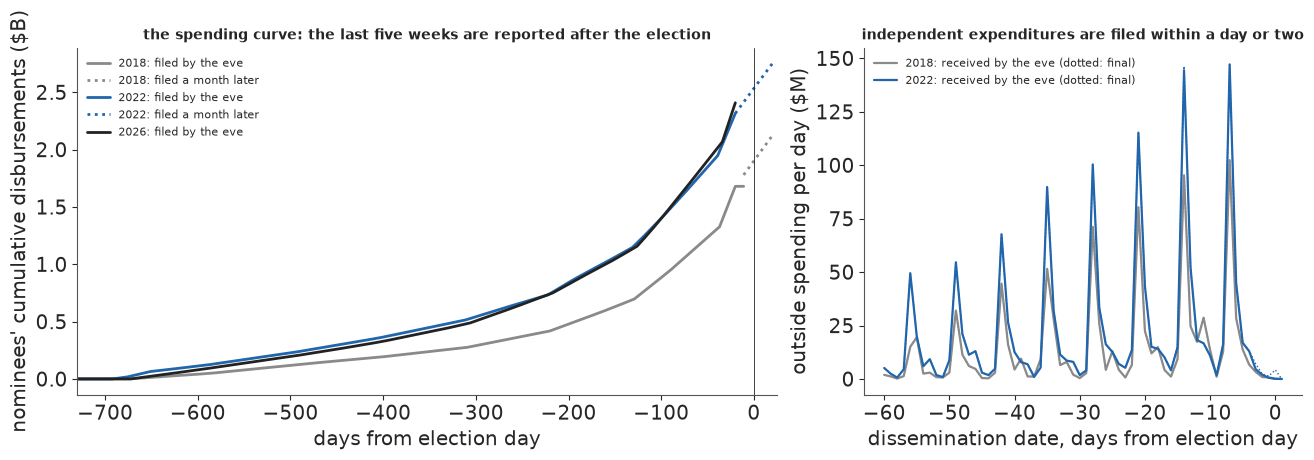

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), width_ratios=[1.6, 1])
ax = axes[0]
for c, col in ((2018, MUTED), (2022, D_C), (2026, INK)):
    w = spend_window(c)
    elec = pd.Timestamp(ELEC[c])
    days, fin = cumulative(w, elec)
    _, kn = cumulative(w[w.receipt <= pd.Timestamp(EVE[c])], elec)
    last = (w[(w.rpt == "12G") & (w.receipt <= pd.Timestamp(EVE[c]))].cvg_end.max() - elec).days  # 12G end
    ax.plot(days[days <= last], kn[days <= last] / 1e9, color=col, lw=2, label=f"{c}: filed by the eve")
    if c < 2026:
        ax.plot(days[days >= last], fin[days >= last] / 1e9, color=col, lw=2, ls=":",
                label=f"{c}: filed a month later")
    SPEND[c]["curve_known_last"] = last
ax.axvline(0, color=INK, lw=0.6)
ax.set_xlim(-730, 25)
ax.set_xlabel("days from election day")
ax.set_ylabel("nominees' cumulative disbursements ($B)")
ax.set_title("the spending curve: the last five weeks are reported after the election", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
for c, col in ((2018, MUTED), (2022, D_C)):
    f = ie[(ie.cycle == c) & (ie.version == "final")]
    eve = pd.Timestamp(EVE[c])
    dd = (f.date - pd.Timestamp(ELEC[c])).dt.days
    days = np.arange(-60, 2)
    tot = np.array([f.amt[dd == k].sum() for k in days]) / 1e6
    seen = np.array([f.amt[(dd == k) & (f.first_receipt <= eve)].sum() for k in days]) / 1e6
    ax.plot(days, tot, color=col, lw=1, ls=":")
    ax.plot(days, seen, color=col, lw=1.6, label=f"{c}: received by the eve (dotted: final)")
ax.set_xlabel("dissemination date, days from election day")
ax.set_ylabel("outside spending per day ($M)")
ax.set_title("independent expenditures are filed within a day or two", fontsize=10)
ax.legend(fontsize=8);

The left panel is the spending curve: cumulative disbursements of all nominees by day, each report
spread evenly over its period. On the eve it is known to 20 days before the election, and 2026's curve
runs almost on top of 2022's. On the right, outside spending filed by the eve and final are nearly the
same line.

### 6.1 The reporting lag of outside money

Outside money needs only a small correction, but it should be a learned one. Let $L$ be the number of
days between an item's dissemination date and the eve. For the dollars disseminated $L$ days before the
eve, the share already received by the eve is $f_L$, and we model the dollars received (in units of
\$100k) as beta-binomial,

$$
\text{seen}_L \sim \text{BetaBinomial}\big(n_L,\ f_L \kappa,\ (1 - f_L)\kappa\big),\qquad
\operatorname{logit} f_L = a + b \log(1 + L),
$$

over daily bins up to two weeks and wider bins beyond. The overdispersion $\kappa$ is there because
dollars arrive in lumps. Dollars dated on election day are modelled as a share $r$ of the last week's
dollars. For a new cycle, the curve is shifted by a cycle effect on the logit scale with an assumed sd of 0.5: the
two cycles cannot estimate how much the lag varies from one cycle to the next. Only one backtest is a
forward test: fitted on 2018, nowcasting 2022 from what had been filed by its eve. The other, fitted on
2022 and nowcasting 2018, runs backwards in time: the 2018 filings are cut at its eve, but the parameters
come from a later cycle, so it is a leave-one-cycle-out check. Report files for other cycles were not
downloaded, so there is no second forward test. The 2026 nowcast fits on both.

In [27]:
LAG_BINS = [(L, L) for L in range(15)] + [(15, 30), (31, 60), (61, 2000)]


def ie_lag_table(cycle, version="final"):
    f = ie[(ie.cycle == cycle) & (ie.version == version)]
    eve = pd.Timestamp(EVE[cycle])
    L = (eve - f.date).dt.days
    rows = []
    for lo, hi in LAG_BINS:
        g = f[(L >= lo) & (L <= hi)]
        rows.append({"cycle": cycle, "lo": lo, "hi": hi, "Lmid": (lo + min(hi, 120)) / 2,
                     "final": g.amt.sum(), "seen": g.amt[g.first_receipt <= eve].sum()})
    week = f.amt[(L >= 0) & (L < 7)].sum()
    return pd.DataFrame(rows), {"week": week, "post": f.amt[L < 0].sum()}


def fit_ie_lag(cycles):
    lag = pd.concat([ie_lag_table(c)[0] for c in cycles])
    post = [ie_lag_table(c)[1] for c in cycles]
    U = 1e5                                     # dollars counted in units of $100k
    with pm.Model() as m:
        a = pm.Normal("a", 0, 2)
        b = pm.Normal("b", 2, 2)
        kappa = pm.Gamma("kappa", 2, 0.05)
        f_L = pm.math.invlogit(a + b * np.log1p(lag.Lmid.to_numpy()))
        pm.BetaBinomial("seen", n=np.round(lag.final.to_numpy() / U).astype(int), alpha=f_L * kappa,
                        beta=(1 - f_L) * kappa, observed=np.round(lag.seen.to_numpy() / U).astype(int))
        # dollars dated election day or later, as a share of the last week's: a cycle-level share
        r_mu = pm.Beta("r_mu", 1, 50)
        r_k = pm.Gamma("r_k", 2, 0.02)
        pm.BetaBinomial("post", n=np.round([p["week"] / U for p in post]).astype(int), alpha=r_mu * r_k,
                        beta=(1 - r_mu) * r_k, observed=np.round([p["post"] / U for p in post]).astype(int))
        idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False, target_accept=0.95)
    return idata


IE_CYCLE_SD = 0.5  # an assumed cycle-wide shift of the lag curve (logit scale): two cycles cannot estimate it


def ie_nowcast(idata, cycle, n=2000, seed=RANDOM_SEED + 1):
    """Draws of a cycle's total general-election IE: seen by the eve, plus lag completion, plus election day.

    Its own seed: predict_late() draws its cycle shift first from RANDOM_SEED, and sharing the stream would
    make the two shifts identical and the candidate and IE parts perfectly anti-correlated."""
    g = np.random.default_rng(seed)
    lag, post = ie_lag_table(cycle, "eve" if cycle == 2026 else "final")
    seen = lag.seen.to_numpy() if cycle < 2026 else lag.final.to_numpy()
    pst = az.extract(idata, num_samples=n, random_seed=seed)
    shift = g.normal(0, IE_CYCLE_SD, (n, 1))
    fL = 1 / (1 + np.exp(-(pst["a"].values[:, None] + shift + pst["b"].values[:, None] * np.log1p(lag.Lmid.to_numpy()))))
    unseen = (seen * (1 / fL - 1)).sum(1)
    r = g.beta(pst["r_mu"].values * pst["r_k"].values, (1 - pst["r_mu"].values) * pst["r_k"].values)
    week_seen = seen[:7].sum()
    return seen.sum() + unseen + r * week_seen, seen.sum()


t0 = time.time()
IE_FIT = {"2018 -> 2022": fit_ie_lag([2018]), "2022 -> 2018": fit_ie_lag([2022]), "both -> 2026": fit_ie_lag([2018, 2022])}
TIMES["IE lag fits"] = time.time() - t0
for k, idt in IE_FIT.items():
    print(k, diagnostics(idt))
print(az.summary(IE_FIT["both -> 2026"], var_names=["a", "b", "kappa", "r_mu"], round_to=3).to_string())
ie_bt = {}
for k, target in (("2018 -> 2022", 2022), ("2022 -> 2018", 2018)):
    tot, seen = ie_nowcast(IE_FIT[k], target)
    q = np.quantile(tot, [0.05, 0.5, 0.95]) / 1e6
    ie_bt[target] = tot
    print(f"IE {k}: seen by the eve ${seen / 1e6:,.0f}M, nowcast ${q[1]:,.1f}M [{q[0]:,.1f}, {q[2]:,.1f}], "
          f"final ${SPEND[target]['ie_final'] / 1e6:,.1f}M")

2018 -> 2022 {'divergences': 0, 'max r_hat': 1.002, 'worst': 'r_k', 'min ESS': 1144, 'tuning': 400}
2022 -> 2018 {'divergences': 0, 'max r_hat': 1.003, 'worst': 'r_k', 'min ESS': 1030, 'tuning': 400}
both -> 2026 {'divergences': 0, 'max r_hat': 1.004, 'worst': 'a', 'min ESS': 980, 'tuning': 400}
         mean      sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
a       1.301   0.443     0.614     2.030  1067.854  1567.482  1.004      0.014    0.008
b       1.116   0.263     0.691     1.529   980.576  1356.130  1.002      0.008    0.005
kappa  29.250  13.908    12.292    54.260  1671.620  2005.590  1.000      0.331    0.325
r_mu    0.012   0.007     0.003     0.026  2628.766  2006.082  1.001      0.000    0.000
IE 2018 -> 2022: seen by the eve $1,609M, nowcast $1,622.8M [1,614.3, 1,643.3], final $1,622.5M
IE 2022 -> 2018: seen by the eve $1,045M, nowcast $1,062.6M [1,051.9, 1,091.4], final $1,048.9M


In the forward test, fitted on 2018, the model nowcast 2022's outside total at \$1,622M (90% interval
1,614 to 1,644) against \$1,622.5M filed. Leaving out 2018 and fitting on 2022, it nowcast 2018 at \$1,063M
(1,052 to 1,092) against \$1,049M: too high by 1.3% and just outside the interval, because 2022 had more
late filers than 2018. The error is tiny next to the candidate side.

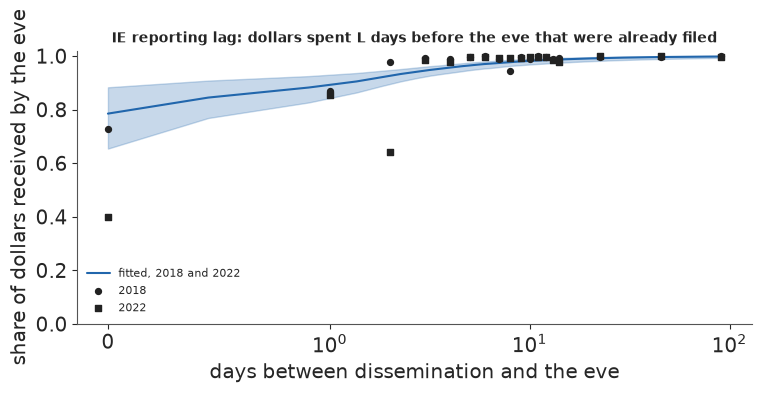

In [28]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
pst = az.extract(IE_FIT["both -> 2026"], num_samples=500, random_seed=RANDOM_SEED)
Ls = np.linspace(0, 90, 200)
fl = 1 / (1 + np.exp(-(pst["a"].values[:, None] + pst["b"].values[:, None] * np.log1p(Ls))))
lo, mid, hi = np.quantile(fl, [0.05, 0.5, 0.95], 0)
ax.fill_between(Ls, lo, hi, color=D_C, alpha=0.25)
ax.plot(Ls, mid, color=D_C, label="fitted, 2018 and 2022")
for c, mk in ((2018, "o"), (2022, "s")):
    t, _ = ie_lag_table(c)
    ax.scatter(t.Lmid, t.seen / t.final, marker=mk, color=INK, s=18, label=str(c), zorder=5)
ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel("days between dissemination and the eve")
ax.set_ylabel("share of dollars received by the eve")
ax.set_ylim(0.0, 1.02)
ax.legend(fontsize=8)
ax.set_title("IE reporting lag: dollars spent L days before the eve that were already filed", fontsize=10);

The points scatter widely in the first two days and sit close to the curve after a week.

### 6.2 Candidates' late spending

A hierarchical growth curve for each race over the whole cycle is more than the eve needs: every
nominee's curve is observed up to mid-October, and only its tail is unknown. The tail is predicted by
how fast the campaign was spending in the 12G period and how much cash it had left. For nominee $j$ in
group $g$ (office x competitiveness: |lean| below 8, 8-20, above 20), with 30G disbursements $y_j$,

$$
\log(1 + y_j) \sim \mathcal N\big(a_g + b_{1g}(x^{\text{rate}}_j - 10) + b_2 (x^{\text{cash}}_j - 12)
+ b_{\text{inc}}\,\text{incumbent}_j,\ \sigma_g\big),\qquad a_g \sim \mathcal N(\mu_a, \sigma_a),
$$

where $x^{\text{rate}}$ is the log of 20 days of spending at the 12G daily rate and $x^{\text{cash}}$
the log of cash on hand at the end of the 12G. Groups pool toward each other through $a_g$. A pilot with
Student-t errors had fine per-candidate coverage but tails that summed to absurd totals (its 90%
interval for the 2022 national total reached \$470B); Normal errors on the log scale fix that. As for
outside money, a shared shift of all candidates in a cycle (a late surge of small donations, say) cannot
be estimated from two cycles, so the nowcast adds one with an assumed sd of 0.25 on the log scale. Both
choices, Normal errors and the sd of 0.25, were made after seeing the pilot's backtests (the pilot,
without a cycle shift, missed 2018 with \$606M, 90% interval 480 to 790, against \$443M filed). The
backtest totals below are therefore not out of sample for those two choices.

**Failure 3, the hierarchy written the other way.** Every group has dozens to hundreds of candidates, so
the data pin each $a_g$ tightly, and that is where the centred form is the right one (E25). The
non-centred form, the usual fix for a funnel, is printed first; then the three fits we use, centred,
with `target_accept=0.95`.

In [29]:
def cand_table(cycle):
    """One row per nominee with reports received by the eve: known spending, the 12G period, and the 30G."""
    r = spend_window(cycle)
    eve = pd.Timestamp(EVE[cycle])
    known = r[r.receipt <= eve]
    k = known.groupby("cand_id").agg(disb_known=("disb", "sum"), race=("race", "first"), office=("office", "first"),
                                     side=("side", "first"))
    p12 = known[known.rpt == "12G"].groupby("cand_id").agg(d12=("disb", "sum"), s12=("cvg_start", "min"),
                                                           e12=("cvg_end", "max"), coh12=("coh", "sum"))
    final = r.groupby("cand_id").disb.sum().rename("disb_final")
    d30 = r[r.rpt == "30G"].groupby("cand_id").disb.sum().rename("d30")
    df = k.join(p12).join(final).join(d30).reset_index()
    rr = R[R.cycle == cycle].set_index("race")
    df["cycle"] = cycle
    df["lean"] = df.race.map(rr.lean)
    df["inc"] = [bool(rr.d_inc.get(rc, False) if s == "D" else rr.r_inc.get(rc, False)) for rc, s in zip(df.race, df.side)]
    df = df[df.d12.notna()].copy()
    df["days12"] = (df.e12 - df.s12).dt.days + 1
    df["x_rate"] = np.log1p(df.d12.clip(0) / df.days12 * 20)     # 20 days at the pre-general burn rate
    df["x_coh"] = np.log1p(df.coh12.clip(0))
    df["comp"] = pd.cut(df.lean.abs().fillna(15), [-1, 8, 20, 200], labels=False).astype(int)
    df["grp"] = (df.office == "S").astype(int) * 3 + df.comp
    return df


GROUPS = [f"{o} {c}" for o in ("House", "Senate") for c in ("|lean|<8", "8-20", ">20")]


def fit_late(df, centred=True):
    t = df[df.d30.notna()]
    g = t.grp.to_numpy()
    with pm.Model(coords={"group": GROUPS}) as m:
        a_mu = pm.Normal("a_mu", 0, 2)
        a_sd = pm.HalfNormal("a_sd", 1)
        if centred:
            a = pm.Normal("a", a_mu, a_sd, dims="group")
        else:
            a = pm.Deterministic("a", a_mu + a_sd * pm.Normal("z_a", 0, 1, dims="group"), dims="group")
        b1 = pm.Normal("b1", 0.5, 0.5, dims="group")
        b2 = pm.Normal("b2", 0.3, 0.5)
        binc = pm.Normal("binc", 0, 0.5)
        sd = pm.HalfNormal("sd", 1, dims="group")
        mu = a[g] + b1[g] * (t.x_rate.to_numpy() - 10) + b2 * (t.x_coh.to_numpy() - 12) + binc * t.inc.to_numpy()
        pm.Normal("y", mu=mu, sigma=sd[g], observed=np.log1p(t.d30.clip(0)).to_numpy())
        idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False, target_accept=0.95)
    return idata


CYCLE_SD = 0.25   # an assumed cycle-wide shift on the log scale: two cycles cannot estimate it


def predict_late(idata, df, n=2000, seed=RANDOM_SEED):
    g_ = np.random.default_rng(seed)
    p = az.extract(idata, num_samples=n, random_seed=seed)
    g = df.grp.to_numpy()
    T = lambda v: p[v].transpose("sample", ...).values  # noqa: E731
    mu = (T("a")[:, g] + T("b1")[:, g] * (df.x_rate.to_numpy() - 10) + T("b2")[:, None] * (df.x_coh.to_numpy() - 12)
          + T("binc")[:, None] * df.inc.to_numpy())
    y = mu + g_.normal(0, CYCLE_SD, (n, 1)) + T("sd")[:, g] * g_.standard_normal(mu.shape)
    return np.expm1(y).clip(0)


CT = {c: cand_table(c) for c in (2018, 2022, 2026)}
for c, t in CT.items():
    print(f"{c}: {len(t)} nominees with a pre-general report by the eve; with a post-general report: "
          f"{int(t.d30.notna().sum())}")
t0 = time.time()
print("non-centred group intercepts, fitted on 2022:", diagnostics(fit_late(CT[2022], centred=False)))
LATE_FIT = {"2018 -> 2022": fit_late(CT[2018]), "2022 -> 2018": fit_late(CT[2022]),
            "both -> 2026": fit_late(pd.concat([CT[2018], CT[2022]]))}
TIMES["late-spending fits"] = time.time() - t0
for k, idt in LATE_FIT.items():
    print(k, diagnostics(idt))
print(az.summary(LATE_FIT["both -> 2026"], var_names=["a", "b1", "b2", "binc", "sd"], round_to=2).to_string())

2018: 826 nominees with a pre-general report by the eve; with a post-general report: 812
2022: 820 nominees with a pre-general report by the eve; with a post-general report: 800
2026: 863 nominees with a pre-general report by the eve; with a post-general report: 0


non-centred group intercepts, fitted on 2022: {'divergences': 13, 'max r_hat': 1.009, 'worst': 'a_sd', 'min ESS': 399, 'tuning': 400}


2018 -> 2022 {'divergences': 0, 'max r_hat': 1.005, 'worst': 'sd', 'min ESS': 1494, 'tuning': 400}
2022 -> 2018 {'divergences': 4, 'max r_hat': 1.007, 'worst': 'b1', 'min ESS': 601, 'tuning': 400}
both -> 2026 {'divergences': 0, 'max r_hat': 1.006, 'worst': 'a_mu', 'min ESS': 1249, 'tuning': 400}


                      mean    sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
a[House |lean|<8]    11.26  0.07     11.14     11.38   1249.33   1659.24    1.0        0.0      0.0
a[House 8-20]        11.13  0.07     11.01     11.25   3472.79   3468.80    1.0        0.0      0.0
a[House >20]         10.90  0.05     10.83     10.98   1973.48   2811.67    1.0        0.0      0.0
a[Senate |lean|<8]   11.10  0.18     10.81     11.38   1454.49   1684.79    1.0        0.0      0.0
a[Senate 8-20]       11.00  0.17     10.72     11.26   1832.93   2226.43    1.0        0.0      0.0
a[Senate >20]        11.15  0.14     10.93     11.38   2524.97   2516.21    1.0        0.0      0.0
b1[House |lean|<8]    0.59  0.02      0.55      0.63   1415.46   2004.32    1.0        0.0      0.0
b1[House 8-20]        0.57  0.03      0.53      0.61   3492.03   3433.83    1.0        0.0      0.0
b1[House >20]         0.54  0.02      0.50      0.57   4037.84   2839.10    1.0        0.0      0.0


The non-centred version had 13 divergences on 2022; the centred one has 0, 4 and 0 in the three fits,
with $\hat R$ at most 1.01. The four remaining divergences sit where the six group intercepts pool
weakly (small $\sigma_a$) and do not move the nowcast. The coefficients are sensible: late spending
rises with the 12G burn rate (elasticity 0.55-0.70) and with cash on hand (0.30), and is about 30% lower
for incumbents. The residual sd is about 0.4 on the log scale for close races and 0.6-1.1 for the
others, where a campaign may simply stop.

In [30]:
bt_rows, LATE_BT = [], {}
for k, target in (("2018 -> 2022", 2022), ("2022 -> 2018", 2018)):
    df = CT[target]
    late = predict_late(LATE_FIT[k], df)
    truth = df.d30.fillna(0).clip(0).to_numpy()
    LATE_BT[target] = (df, late, truth)
    tot = late.sum(1)
    pit = (late < truth).mean(0) + 0.5 * (late == truth).mean(0)
    lo, hi = np.quantile(late, [0.05, 0.95], 0)
    bt_rows.append({"fit -> target": k, "late, true $M": truth.sum() / 1e6,
                    "late, nowcast $M": np.median(tot) / 1e6, "90% lo": np.quantile(tot, 0.05) / 1e6,
                    "90% hi": np.quantile(tot, 0.95) / 1e6, "PIT of the total": (tot < truth.sum()).mean(),
                    "per-candidate 90% cover": np.mean((truth >= lo) & (truth <= hi)),
                    "per-candidate 50% cover": np.mean((truth >= np.quantile(late, 0.25, 0)) & (truth <= np.quantile(late, 0.75, 0)))})
print(pd.DataFrame(bt_rows).round(2).to_string(index=False))

fit -> target  late, true $M  late, nowcast $M  90% lo  90% hi  PIT of the total  per-candidate 90% cover  per-candidate 50% cover
 2018 -> 2022         434.26            481.32  315.40  725.53              0.34                     0.92                     0.64
 2022 -> 2018         442.58            622.91  395.88  991.22              0.12                     0.93                     0.68


In the forward test, fitted on 2018, the nowcast of 2022's late spending is \$481M (90% interval 315 to
726) against \$434M filed: inside, a little high (PIT 0.34). Leaving out 2018, it nowcasts 2018 at \$623M
(396 to 991) against \$443M: inside, but in the lower tail (PIT 0.12). So the evidence on totals is two
totals, both over-predicted, one of them a forward test, and the cycle shift that puts both inside was
sized after the pilot had seen them. Per candidate, the 90% intervals cover 92-93% and the 50% intervals
64-68%: a little too wide in the middle, as the humped PIT below shows.

In [31]:
def race_totals(cycle, late, df, ie_tot=None):
    """Per-race spending: nominees' known + late draws, plus IE (final, or seen + scaled-up for 2026)."""
    races_ = sorted(df.race.unique())
    idx = pd.Index(races_).get_indexer(df.race)
    S = late.shape[0]
    cand = np.zeros((S, len(races_)))
    np.add.at(cand.T, idx, (late + df.disb_known.to_numpy()).T)
    f = ie[(ie.cycle == cycle) & (ie.version == ("eve" if cycle == 2026 else "final"))]
    if cycle < 2026:
        f_seen = f[f.first_receipt <= pd.Timestamp(EVE[cycle])]
    else:
        f_seen = f
    ie_seen = f_seen.groupby("race").amt.sum().reindex(races_).fillna(0).to_numpy()
    scale = (ie_tot / f_seen.amt.sum())[:, None] if ie_tot is not None else 1.0
    return races_, cand + ie_seen[None, :] * scale


rt_rows = []
for target in (2018, 2022):
    df, late, truth = LATE_BT[target]
    races_, draws = race_totals(target, late, df, ie_bt[target])
    f = ie[(ie.cycle == target) & (ie.version == "final")]
    true_race = (df.groupby("race").disb_final.sum().reindex(races_).to_numpy()
                 + f.groupby("race").amt.sum().reindex(races_).fillna(0).to_numpy())
    lo, hi = np.quantile(draws, [0.05, 0.95], 0)
    top = np.argsort(-true_race)[:50]
    rt_rows.append({"target": target, "races": len(races_), "90% cover, all races": np.mean((true_race >= lo) & (true_race <= hi)),
                    "90% cover, 50 costliest": np.mean((true_race[top] >= lo[top]) & (true_race[top] <= hi[top])),
                    "median abs error, 50 costliest (%)": 100 * np.median(np.abs(np.median(draws, 0)[top] / true_race[top] - 1))})
print(pd.DataFrame(rt_rows).round(3).to_string(index=False))

 target  races  90% cover, all races  90% cover, 50 costliest  median abs error, 50 costliest (%)
   2018    468                 0.964                     0.96                               2.163
   2022    470                 0.962                     0.98                               1.827


By race, adding each race's filed spending and outside money, the nowcast's 90% intervals cover 96% of
race totals in both backtests, and the median error for the 50 costliest races is about 2%: by the eve
most of a race's money is already on file, and the nowcast only has to supply the tail.

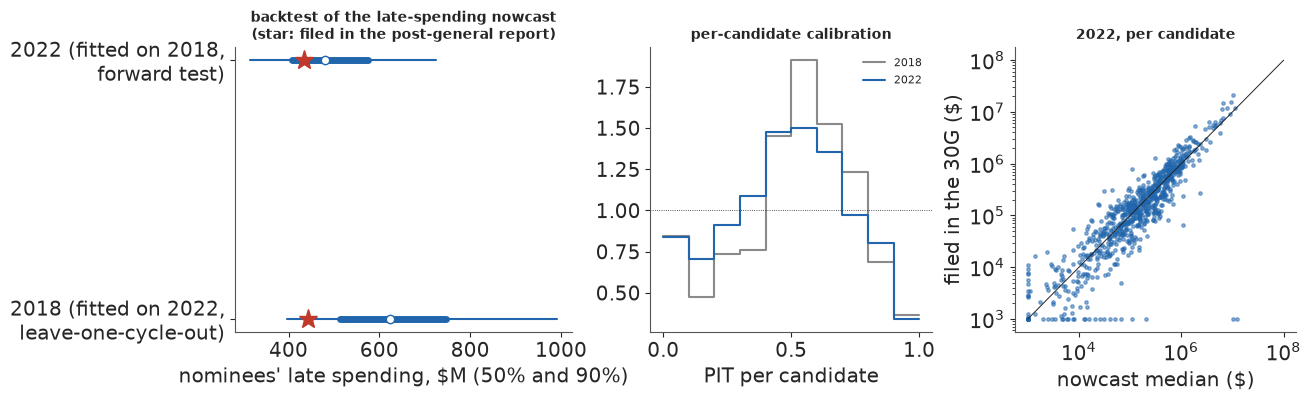

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), width_ratios=[1.2, 1, 1])
ax = axes[0]
for k, target in enumerate((2018, 2022)):
    df, late, truth = LATE_BT[target]
    tot = late.sum(1) / 1e6
    parts = np.quantile(tot, [0.05, 0.25, 0.5, 0.75, 0.95])
    ax.plot([parts[0], parts[4]], [k, k], color=D_C, lw=1.5)
    ax.plot([parts[1], parts[3]], [k, k], color=D_C, lw=5)
    ax.plot(parts[2], k, "o", color="white", mec=D_C)
    ax.plot(truth.sum() / 1e6, k, "*", color=R_C, ms=14)
ax.set_yticks([0, 1], ["2018 (fitted on 2022,\nleave-one-cycle-out)", "2022 (fitted on 2018,\nforward test)"])
ax.set_xlabel("nominees' late spending, $M (50% and 90%)")
ax.set_title("backtest of the late-spending nowcast\n(star: filed in the post-general report)", fontsize=10)
ax = axes[1]
for target, col in ((2018, MUTED), (2022, D_C)):
    df, late, truth = LATE_BT[target]
    pit = (late < truth).mean(0) + 0.5 * (late == truth).mean(0)
    h, e = np.histogram(pit, bins=10, range=(0, 1))
    ax.step(e, np.r_[h, h[-1]] / h.sum() * 10, where="post", color=col, label=str(target))
ax.axhline(1, color=INK, lw=0.6, ls=":")
ax.set_xlabel("PIT per candidate")
ax.legend(fontsize=8)
ax.set_title("per-candidate calibration", fontsize=10)
ax = axes[2]
df, late, truth = LATE_BT[2022]
med = np.median(late, 0)
ax.scatter(np.maximum(med, 1e3), np.maximum(truth, 1e3), s=6, alpha=0.5, color=D_C)
ax.plot([1e3, 1e8], [1e3, 1e8], color=INK, lw=0.7)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("nowcast median ($)")
ax.set_ylabel("filed in the 30G ($)")
ax.set_title("2022, per candidate", fontsize=10);

The backtest figure shows both totals inside their intervals, the 2018 total near the lower edge. The
per-candidate PITs are humped; the scatter of nowcast against filed spending for 2022 follows the
diagonal over four orders of magnitude, with a row of candidates at the bottom who filed nothing more
(they count as zero, as the 2026 total will).

## 7 · 2026: the frozen forecast and nowcast

There are two frozen forecasts, both made on 3 November 2026 before any polls closed, both from
information dated up to 2 November, and both will be scored.

* **v1, pre-registered** (`e94_freeze_2026.json`): written by the pilot code in `tools/e94_pilot/` at
  18:17 UTC and committed with its inputs and code in `e9c37e7` at 19:09:40 UTC.
* **v2, corrected** (`e94_freeze_2026_v2.json`): written by `tools/e94_freeze_v2.py`, which runs this
  notebook's code, at 19:18:45 UTC and committed in `77d2c05` at 19:18:56 UTC.

v2 exists because of a mistake in v1's data. The builder matched 2026 nominees to FEC IDs by name, only
among candidates who had filed a pre-general report, and gave an unmatched nominee \$0 of receipts. That
missed 14% of Republican nominees, including Ashley Hinson in Iowa's Senate race (the FEC files her as
"ARENHOLZ, ASHLEY HINSON"), and pinned the money signal of 61 races at its clip, worth about 12 points
of margin. v2 matches against the FEC's full candidate list and treats the two nominees still unmatched
as missing. v1 stays the pre-registered record; scoring both shows what the mistake cost. Each file
stores the sha256 of its inputs.

In [33]:
def sha(p, content=False):
    b = open(p, "rb").read()
    return hashlib.sha256(gzip.decompress(b) if content and str(p).endswith(".gz") else b).hexdigest()


FROZEN1 = json.load(open(data.path("e94_freeze_2026")))        # v1: pre-registered, commit e9c37e7
FROZEN = json.load(open(data.path("e94_freeze_2026_v2")))      # v2: corrected, same information cutoff
V1_INPUTS = json.load(open(data.path("e94_freeze_2026_v1_inputs")))
for lab, fz_ in (("v1", FROZEN1), ("v2", FROZEN)):
    print(f"{lab}: frozen at {fz_['frozen_at_utc']} | information cutoff: {fz_['information_cutoff'][:10]} | "
          f"sha256 {sha(data.path('e94_freeze_2026' + ('_v2' if lab == 'v2' else '')))[:16]}...")
for fname, h in FROZEN["inputs_sha256"].items():
    p = data.DATA_DIR / fname
    same_raw = sha(p) == h
    same_v2 = sha(p, True) == FROZEN["inputs_sha256_content"][fname]
    same_v1 = sha(p, True) == V1_INPUTS["content_sha256"][fname]
    print(f"  input {fname:20s} v2: {'unchanged' if same_v2 else 'CHANGED'} (content), "
          f"{'same bytes' if same_raw else 'other bytes'}; v1 ({V1_INPUTS['commit'][:7]}): "
          f"{'unchanged' if same_v1 else 'rebuilt since'}")

v1: frozen at 2026-11-03T18:17:11Z | information cutoff: 2026-11-02 | sha256 0b7712887bdc71a1...
v2: frozen at 2026-11-03T19:18:45Z | information cutoff: 2026-11-02 | sha256 de18642ab75047eb...
  input e94_races.csv        v2: unchanged (content), same bytes; v1 (e9c37e7): rebuilt since
  input e94_polls.csv        v2: unchanged (content), same bytes; v1 (e9c37e7): unchanged
  input e94_reports.csv.gz   v2: unchanged (content), same bytes; v1 (e9c37e7): rebuilt since
  input e94_ie.csv.gz        v2: unchanged (content), same bytes; v1 (e9c37e7): rebuilt since
  input e94_pollerr.csv      v2: unchanged (content), same bytes; v1 (e9c37e7): unchanged


The inputs on disk are exactly v2's. Three of v1's inputs were rebuilt for v2, by design; v1's own
inputs are in commit `e9c37e7`, and the content hashes of all five are kept in a separate file so that
a rebuild that only changes gzip header bytes does not look like a change.

In [34]:
s26 = fit26["seats"]
notup = {k: int(v) for k, v in build_log["senate_2026_not_up"].items()}
sen26 = s26["S"] + notup["Democratic"] + notup["Independent"]
q = lambda v: np.quantile(v, [0.05, 0.5, 0.95])  # noqa: E731


def frozen_col(f):
    fs_ = f["seats"]
    iv = lambda v, fmt: f"{v[1]:{fmt}} [{v[0]:{fmt}}, {v[2]:{fmt}}]"  # noqa: E731
    return [iv(fs_["N_q05_q50_q95"], "+.1f"), iv(fs_["H"]["D_seats_q05_q50_q95"], ".0f"),
            iv(fs_["S"]["D_seats_q05_q50_q95"], ".0f"), f"{fs_['H']['P_D_control']:.2f}", f"{fs_['S']['P_D_control']:.2f}"]


cmp = pd.DataFrame({
    "v1 (pre-registered)": frozen_col(FROZEN1), "v2 (corrected)": frozen_col(FROZEN),
    "this run": [f"{q(fit26['N'])[1]:+.1f} [{q(fit26['N'])[0]:+.1f}, {q(fit26['N'])[2]:+.1f}]",
                 f"{q(s26['H'])[1]:.0f} [{q(s26['H'])[0]:.0f}, {q(s26['H'])[2]:.0f}]",
                 f"{q(sen26)[1]:.0f} [{q(sen26)[0]:.0f}, {q(sen26)[2]:.0f}]",
                 f"{(s26['H'] >= 218).mean():.2f}", f"{(sen26 >= 51).mean():.2f}"]},
    index=["national margin N", "House D seats", "Senate D-caucus seats", "P(D House majority)", "P(D Senate control)"])
print(cmp.to_string())
fz = pd.DataFrame(FROZEN["races"]).set_index("race")
fz1 = pd.DataFrame(FROZEN1["races"]).set_index("race")
tm26 = fit26["d"]["tm"].assign(pD=(fit26["sim"] > 0).mean(0), med=np.median(fit26["sim"], 0))
j = tm26.join(fz, on="race", rsuffix="_frozen")
print(f"race by race, this run against v2: P(D) differs by {np.abs(j.pD - j.pD_frozen).mean():.3f} on average "
      f"(largest {np.abs(j.pD - j.pD_frozen).max():.2f}); median margins by {np.abs(j.med - j.pred).mean():.2f} points")
v12 = fz1[["pD", "pred"]].join(fz[["pD", "pred"]], rsuffix="_v2").join(tm26.set_index("race")[["r_name"]])
v12["shift"] = v12.pred_v2 - v12.pred
print("largest changes from v1 to v2 (median D margin, points):")
print(v12.reindex(v12["shift"].abs().sort_values(ascending=False).index).head(8).round(2).to_string())

                      v1 (pre-registered)      v2 (corrected)            this run
national margin N      +7.9 [+3.2, +12.8]  +7.8 [+3.0, +12.9]  +7.8 [+3.1, +12.7]
House D seats              236 [217, 261]      236 [217, 262]      237 [217, 262]
Senate D-caucus seats         52 [49, 56]         52 [48, 56]         52 [48, 56]
P(D House majority)                  0.95                0.94                0.94
P(D Senate control)                  0.83                0.78                0.79
race by race, this run against v2: P(D) differs by 0.002 on average (largest 0.04); median margins by 0.15 points
largest changes from v1 to v2 (median D margin, points):
         pD   pred  pD_v2  pred_v2            r_name  shift
race                                                       
CA-45  1.00  28.68   1.00    21.48         Chuong Vo  -7.20
FL-28  0.00 -19.09   0.03   -13.96    Carlos Giménez   5.13
MD-04  1.00  85.35   1.00    90.40  George McDermott   5.05
ID-S   0.06  -8.62   0.01   -13.61   

The corrected freeze, v2, puts the national House margin at D+7.8 (90% interval 3.0 to 12.9) and the
Democrats at 236 House seats (217 to 262) with a 0.94 chance of a majority, and 52 Democratic-caucus
Senate seats (48 to 56) with a 0.78 chance of control. The pre-registered v1 said D+7.9 (3.2 to 12.8),
236 (217 to 261), 0.95, and 52 (49 to 56) with 0.83. This run matches v2 within sampling noise. The
Senate count includes the 34 seats not up (32 Democrats and 2 independents who caucus with them), and a
50-50 Senate goes to the Republicans through Vice President Vance.

The correction moves the races whose nominee was missed. Iowa's Senate race goes from D+5.5 with
P(D) = 0.87 to D+0.8 with 0.57, closer to its polls, and Idaho's moves 5 points toward Jim Risch (whose
FEC party is "UNK"); together they lower the chance of Senate control from 0.83 to 0.78. California's
45th moves 7 points toward the Republican. The House totals hardly move, because most of the missed
nominees ran in safe seats.

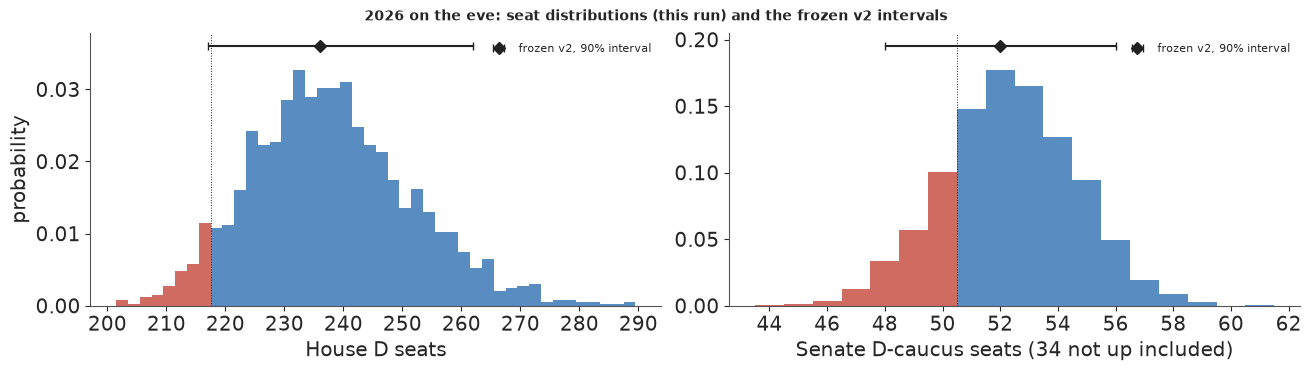

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, v, off, line, lab in ((axes[0], s26["H"], "H", 217.5, "House D seats"),
                              (axes[1], sen26, "S", 50.5, "Senate D-caucus seats (34 not up included)")):
    w_ = 2 if off == "H" else 1
    e = np.arange(v.min() - 0.5, v.max() + w_, w_)
    cnt, _ = np.histogram(v, e)
    cnt = cnt / len(v) / w_
    ax.bar(e[:-1], cnt, width=w_, align="edge", color=np.where(e[:-1] + w_ / 2 > line, D_C, R_C), alpha=0.75)
    fq = FROZEN["seats"][off]["D_seats_q05_q50_q95"]
    ax.errorbar(fq[1], cnt.max() * 1.1, xerr=[[fq[1] - fq[0]], [fq[2] - fq[1]]], fmt="D", color=INK, capsize=3,
                label="frozen v2, 90% interval")
    ax.axvline(line, color=INK, lw=0.7, ls=":")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel(lab)
    ax.legend(fontsize=8, loc="upper right")
axes[0].set_ylabel("probability")
fig.suptitle("2026 on the eve: seat distributions (this run) and the frozen v2 intervals", fontsize=10);

The House distribution is wide and right-skewed, with most of its mass above the 218 line; the Senate
distribution is centred at 52, one seat above the 51 that control needs, with a real chance of 50 or
fewer.

of the 30 closest frozen races, 22 have race polls; House seat 218 from the Democratic end has frozen P(D) = 0.76


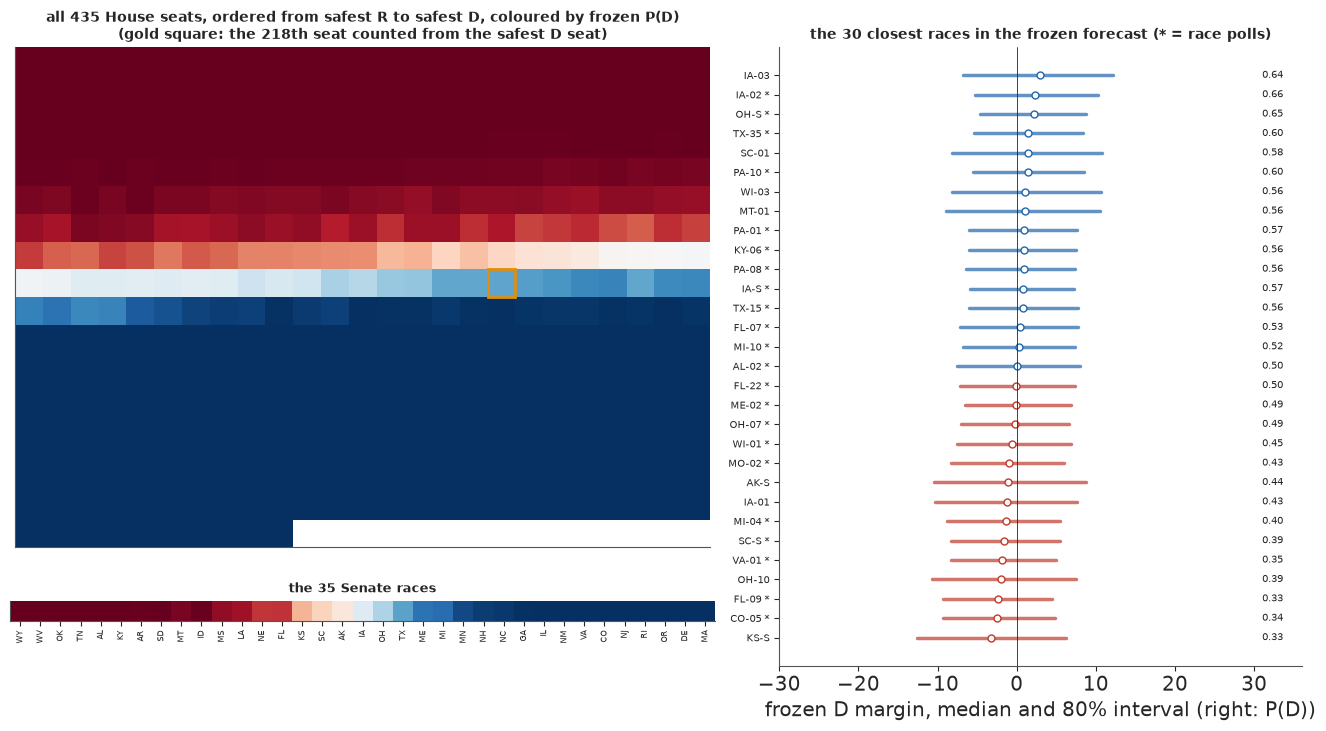

In [36]:
fig = plt.figure(figsize=(13, 7.2))
gs = fig.add_gridspec(2, 2, width_ratios=[1.35, 1], height_ratios=[1, 0.22])
ax = fig.add_subplot(gs[:, 1])
pDall = fit26["d"]["tgt"][["race", "office", "state"]].merge(fz[["pD", "pred", "q10", "q90"]], left_on="race",
                                                             right_index=True, how="left")
close = fz.assign(unc=np.abs(fz.pD - 0.5)).sort_values("unc").head(30).sort_values("pred")
polled26 = set(fit26["d"]["polled"])
print(f"of the 30 closest frozen races, {sum(r in polled26 for r in close.index)} have race polls; "
      f"House seat 218 from the Democratic end has frozen P(D) = "
      f"{np.sort(np.r_[np.zeros(int((~fit26['d']['tgt'].modelled & (fit26['d']['tgt'].office == 'H') & (fit26['d']['tgt'].d_name.fillna('') == '')).sum())), fz[fz.office == 'H'].pD.to_numpy(), np.ones(int((~fit26['d']['tgt'].modelled & (fit26['d']['tgt'].office == 'H') & (fit26['d']['tgt'].d_name.fillna('') != '')).sum()))])[435 - 218]:.2f}")
for k, (race, r) in enumerate(close.iterrows()):
    col = D_C if r.pred > 0 else R_C
    ax.plot([r.q10, r.q90], [k, k], color=col, lw=2.5, alpha=0.7)
    ax.plot(r.pred, k, "o", color="white", mec=col, ms=5)
    ax.text(31, k, f"{r.pD:.2f}", va="center", fontsize=7, color=INK)
ax.set_yticks(range(len(close)), [f"{r}{' *' if r in polled26 else ''}" for r in close.index], fontsize=7)
ax.axvline(0, color=INK, lw=0.6)
ax.set_xlim(-30, 36)
ax.set_xlabel("frozen D margin, median and 80% interval (right: P(D))")
ax.set_title("the 30 closest races in the frozen forecast (* = race polls)", fontsize=10)
axg = fig.add_subplot(gs[0, 0])
hz = fz[fz.office == "H"].sort_values("pred")
uncont = fit26["d"]["tgt"][(fit26["d"]["tgt"].office == "H") & ~fit26["d"]["tgt"].modelled]
ncol = 25
vals = np.r_[np.ones(int((uncont.d_name.fillna("") == "").sum())) * 0.0, hz.pD.to_numpy(),
             np.ones(int((uncont.d_name.fillna("") != "").sum()))]
grid = np.full(int(np.ceil(len(vals) / ncol)) * ncol, np.nan)
grid[: len(vals)] = vals
axg.imshow(grid.reshape(-1, ncol), cmap="RdBu", vmin=0, vmax=1, aspect="equal")
k218 = 435 - 218
axg.add_patch(plt.Rectangle((k218 % ncol - 0.5, k218 // ncol - 0.5), 1, 1, fill=False, ec=GOLD, lw=2))
axg.set_xticks([])
axg.set_yticks([])
axg.set_title("all 435 House seats, ordered from safest R to safest D, coloured by frozen P(D)\n"
              "(gold square: the 218th seat counted from the safest D seat)", fontsize=10)
axs = fig.add_subplot(gs[1, 0])
sz = fz[fz.office == "S"].sort_values("pred")
axs.imshow(sz.pD.to_numpy()[None, :], cmap="RdBu", vmin=0, vmax=1, aspect="equal")
axs.set_xticks(range(len(sz)), [r.replace("-S", "").replace("2", "") for r in sz.index], fontsize=6, rotation=90)
axs.set_yticks([])
axs.set_title("the 35 Senate races", fontsize=9);

The grid shows every House seat as one tile, ordered from the safest Republican seat to the safest
Democratic one, coloured by v2's chance of a Democratic win. The gold tile, the 218th seat counted from
the Democratic end, sits in the light blue: the seat that decides the majority leans Democratic. Of the
30 closest races on the right, 22 have race polls (marked *); the other 8 rest on the fundamentals.

A distribution of seat counts is hard to feel. Each predictive draw is one complete election: every race
gets a margin, and all of them share one national environment, one set of state effects and one polling
error. The animation plays thirty of them. They are taken evenly across the distribution of Democratic
House seats (the draws at the 2nd, 5th, 8th and so on up to the 98th percentile), so a Republican House
turns up about as often as the forecast says it should, and they run from the worst Democratic outcome to
the best. The left panel colours each state with a Senate race by its margin in that draw. The right panel
is the House grid from above, coloured by margin instead of by probability. The states are drawn from the
county outlines used in E16 and E89; a state border is any county edge the state shares with another
state. There is no district map, because several states redrew their lines for 2026 and the repository
has no boundary file for the new districts.

In [37]:
FIPS = {"01": "AL", "02": "AK", "04": "AZ", "05": "AR", "06": "CA", "08": "CO", "09": "CT", "10": "DE", "11": "DC",
        "12": "FL", "13": "GA", "15": "HI", "16": "ID", "17": "IL", "18": "IN", "19": "IA", "20": "KS", "21": "KY",
        "22": "LA", "23": "ME", "24": "MD", "25": "MA", "26": "MI", "27": "MN", "28": "MS", "29": "MO", "30": "MT",
        "31": "NE", "32": "NV", "33": "NH", "34": "NJ", "35": "NM", "36": "NY", "37": "NC", "38": "ND", "39": "OH",
        "40": "OK", "41": "OR", "42": "PA", "44": "RI", "45": "SC", "46": "SD", "47": "TN", "48": "TX", "49": "UT",
        "50": "VT", "51": "VA", "53": "WA", "54": "WV", "55": "WI", "56": "WY"}


def place(ring, st):
    """Lower 48 as longitude and latitude; Alaska and Hawaii moved and scaled into the corner."""
    x, y = ring[:, 0], ring[:, 1]
    if st == "AK":
        x, y = -118 + (x + 152) * 0.2, 25 + (y - 63) * 0.35
    elif st == "HI":
        x, y = -104 + (x + 157), 25 + (y - 20.5)
    return np.c_[x, y]


rings, ring_state = [], []
for ft in json.load(open(data.path("us_counties_geojson")))["features"]:
    st = FIPS.get(ft["properties"]["STATE"])
    geom = ft["geometry"]
    polys = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
    for poly in polys:
        ring = np.asarray(poly[0], float)
        if st and not (st == "AK" and ring[:, 0].max() > 0):      # Aleutians past 180 degrees dropped
            rings.append(place(ring, st))
            ring_state.append(st)
ring_state = np.array(ring_state)
seen_ = {}
for ring, st in zip(rings, ring_state):                          # state borders, no GIS dissolve (E89)
    r_ = np.round(ring, 3)
    for a_, b_ in zip(map(tuple, r_[:-1]), map(tuple, r_[1:])):
        seen_.setdefault((a_, b_) if a_ < b_ else (b_, a_), set()).add(st)
borders = [e for e, g_ in seen_.items() if len(g_) > 1]

tm_a = fit26["d"]["tm"]
sim26 = fit26["sim"]
sen_i = np.flatnonzero((tm_a.office == "S").to_numpy())
sen_col = {st: i for st, i in zip(tm_a.state.to_numpy()[sen_i], sen_i)}
ring_race = np.array([sen_col.get(st, -1) for st in ring_state])
h_i = np.flatnonzero((tm_a.office == "H").to_numpy())
h_i = h_i[np.argsort(np.median(sim26[:, h_i], 0))]               # safest R to safest D
tgt26 = fit26["d"]["tgt"]
unc = tgt26[(tgt26.office == "H") & ~tgt26.modelled]
n_r, n_d = int((unc.d_name.fillna("") == "").sum()), int((unc.d_name.fillna("") != "").sum())
ncol = 29
n_tiles = n_r + len(h_i) + n_d
gx, gy = np.arange(n_tiles) % ncol, np.arange(n_tiles) // ncol

n_frames = 30
house_draws = seats(fit26["d"], sim26)["H"]
by_seats = np.argsort(house_draws, kind="stable")
pick = by_seats[((np.arange(n_frames) + 0.5) / n_frames * len(sim26)).astype(int)]  # evenly spaced in rank
norm = plt.Normalize(-20, 20)
cmap = plt.get_cmap("RdBu").copy()
cmap.set_bad(LIGHT)

fig, (axm, axh) = plt.subplots(1, 2, figsize=(11, 4.2), width_ratios=[1.45, 1], dpi=60)
pc = PolyCollection(rings, cmap=cmap, norm=norm, edgecolor="face", linewidth=0.4)   # no seams between counties
axm.add_collection(pc)
axm.add_collection(LineCollection(borders, color="white", lw=0.5))
axm.set_xlim(-125, -66)
axm.set_ylim(17, 50)
axm.set_aspect(1 / np.cos(np.radians(38)))
axm.set_axis_off()
axm.set_title("Senate: D margin by state (grey: no race)", fontsize=9)
tiles = axh.scatter(gx, -gy, c=np.zeros(n_tiles), cmap=cmap, norm=norm, marker="s", s=40, linewidths=0)
k218 = n_tiles - 218
axh.scatter([gx[k218]], [-gy[k218]], marker="s", s=64, facecolor="none", edgecolor=GOLD, lw=1.6)
axh.set_axis_off()
axh.set_aspect("equal")
axh.set_title("House: 435 seats, safest R to safest D\n(gold: the 218th seat from the D end)", fontsize=9)
fig.colorbar(plt.cm.ScalarMappable(norm, cmap), ax=[axm, axh], orientation="horizontal", fraction=0.04, pad=0.02,
             label="D minus R margin in this draw (points; clipped at 20)")
title = fig.suptitle("", fontsize=10)


def show_draw(k):
    s_ = sim26[pick[k]]
    pc.set_array(np.ma.masked_array(np.where(ring_race >= 0, s_[ring_race], 0.0), ring_race < 0))
    tiles.set_array(np.r_[np.full(n_r, -100.0), s_[h_i], np.full(n_d, 100.0)])
    hd = n_d + int((s_[h_i] > 0).sum())
    sd = int((s_[sen_i] > 0).sum()) + notup["Democratic"] + notup["Independent"]
    title.set_text(f"Draw {k + 1} of {n_frames}, from fewest to most D House seats: House D {hd} "
                   f"({'D' if hd >= 218 else 'R'} majority), Senate D caucus {sd} ({'D' if sd >= 51 else 'R'} control)")
    return [pc, tiles, title]


show_draw(0)
anim = animation.FuncAnimation(fig, show_draw, frames=n_frames, interval=600)
plt.close(fig)
hd_all = house_draws[pick]
print(f"{n_frames} draws: the Democrats hold the House in {(hd_all >= 218).sum()} and the Senate in "
      f"{int(((sim26[pick][:, sen_i] > 0).sum(1) + notup['Democratic'] + notup['Independent'] >= 51).sum())}; "
      f"{len(rings):,} county polygons, {len(borders):,} border edges")
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    anim_html = anim.to_jshtml(default_mode="loop")
print(f"animation: {len(anim_html) / 1e6:.1f} MB")
HTML(anim_html)

30 draws: the Democrats hold the House in 28 and the Senate in 20; 3,326 county polygons, 9,208 border edges


animation: 2.3 MB


The Democrats hold the House in 28 of the 30 frames, close to the forecast's 0.94. They hold the Senate in
20, fewer than the 24 that 0.79 implies, but the frames were chosen to cover the House distribution, and
thirty frames are a small sample of the Senate. The point of watching is that the races move together.
In the early frames the middle rows of the grid turn red together, and Iowa, Ohio, Alaska and Texas move
the same way, because $N$, the shared error and the state effects shift every race at once. Each race
also has its own noise, so a few seats and states go against the tide in every frame. Between them,
those two kinds of variation make the seat distribution wide.

### 7.1 If the Democrats fall short of their polls

Both frozen forecasts centre the shared polling error on zero: the polls are as likely to overstate the
Democrats as the Republicans. After 2016, 2020 and 2024 a common worry is that they lean one way, and that
Democrats tend to underperform their polls. This section asks what the record says, and how much the 2026
forecast depends on the answer. Both analyses were added on election day, after the freezes, and are not
part of either frozen forecast.

In [38]:
gen_err = pollerr[pollerr.generic].set_index("cycle").err
sen_err = pollerr[~pollerr.generic & (pollerr.type_simple == "Sen-G")].groupby("cycle").err.mean()
hist = pd.DataFrame({"generic ballot": gen_err, "Senate, mean of races": sen_err})
hist = hist[hist.index % 2 == 0]                     # drop the odd-year Senate specials
hist["midterm"] = hist.index.isin(PRES)
print("mean signed error of the last three weeks' polls, D minus R margin (positive: the polls overstated the Democrats)")
print(hist.drop(columns="midterm").round(1).T.to_string())
for lab, sel in (("midterms", hist.midterm), ("presidential years", ~hist.midterm)):
    h_ = hist[sel]
    print(f"{lab:19s}: generic ballot {h_['generic ballot'].mean():+.1f} on average, overstating the Democrats in "
          f"{(h_['generic ballot'] > 0).sum()} of {len(h_)}; Senate {h_['Senate, mean of races'].mean():+.1f}, "
          f"{(h_['Senate, mean of races'] > 0).sum()} of {len(h_)}")
MID_GEN = {c: float(hist[(hist.index < c) & hist.midterm]["generic ballot"].mean()) for c in (2018, 2022, 2026)}
print("mean midterm generic-ballot error before each target:", {c: round(v, 2) for c, v in MID_GEN.items()})
b26 = np.quantile(fit26["bias"], [0.05, 0.5, 0.95])
print(f"2026 shared error: prior Normal(0, {PERR[2026]['shared']:.1f}); posterior median {b26[1]:+.1f} "
      f"[{b26[0]:+.1f}, {b26[2]:+.1f}]; P(error > {MID_GEN[2026]:.1f}) = {(fit26['bias'] > MID_GEN[2026]).mean():.2f}")

mean signed error of the last three weeks' polls, D minus R margin (positive: the polls overstated the Democrats)
cycle                  1998  2000  2002  2004  2006  2008  2010  2012  2014  2016  2018  2020  2022
generic ballot          2.8   2.3   5.3   4.6   6.3  -1.9  -0.3  -0.8   3.2   3.6  -1.2   4.9   2.3
Senate, mean of races  -2.8  -2.5   1.2   2.4  -2.6  -1.3  -1.2  -3.3   3.1   5.0   0.5   6.4   1.0
midterms           : generic ballot +2.6 on average, overstating the Democrats in 5 of 7; Senate -0.1, 4 of 7
presidential years : generic ballot +2.1 on average, overstating the Democrats in 4 of 6; Senate +1.1, 3 of 6
mean midterm generic-ballot error before each target: {2018: 3.45, 2022: 2.68, 2026: 2.63}
2026 shared error: prior Normal(0, 3.3); posterior median +1.2 [-3.7, +5.8]; P(error > 2.6) = 0.30


For national polls, the record supports the worry. In their last three weeks, generic-ballot polls
overstated the Democrats in 9 of the 13 cycles since 1998: in 5 of 7 midterms, by 2.6 points on average,
and in 4 of 6 presidential years, by 2.1. Senate polls show no such lean in midterms (-0.1 on average, 4
of 7) and a modest one in presidential years (+1.1). The errors are large and change sign from cycle to
cycle. 2018 understated the Democrats by 1.2 points and 2006 overstated them by 6.3. With seven midterms,
the mean of 2.6 has a standard error of about 1 point.

The model already leans that way a little. Its posterior for the 2026 shared error has a median of +1.2
points (90% interval -3.7 to +5.8), because the midterm prior (D+4.3) is less Democratic than the polls
(about D+9). The model splits the gap between them, and the part it gives to the polls is read as
polling error. It puts a 30% chance on an error larger than the midterm average of 2.6.

 shortfall  P(D House)  P(D Senate)   H q5  H q50  H q95  S q5  S q50  S q95
      -1.0        0.97         0.87 220.00  241.0  267.0  49.0   53.0   57.0
       0.0        0.94         0.79 217.00  237.0  262.0  48.0   52.0   56.0
       1.0        0.90         0.70 213.95  233.0  257.0  48.0   52.0   56.0
       2.0        0.84         0.60 211.00  228.0  252.0  47.0   51.0   55.0
       3.0        0.74         0.49 208.00  225.0  247.0  47.0   50.0   54.0
       4.0        0.62         0.38 205.00  221.0  242.0  46.0   50.0   54.0
       5.0        0.49         0.27 203.00  217.0  237.0  45.0   49.0   53.0
       6.0        0.36         0.19 200.00  214.0  233.0  45.0   49.0   52.0
shortfall at which control is a coin flip: House 4.9 points, Senate 2.9 points
median House seats: 237 with no shortfall, 225 with 3 points (4.0 seats per point)


/tmp/ipykernel_2528106/324713191.py:45: UserWarning: The figure layout has changed to tight
  fig.tight_layout();


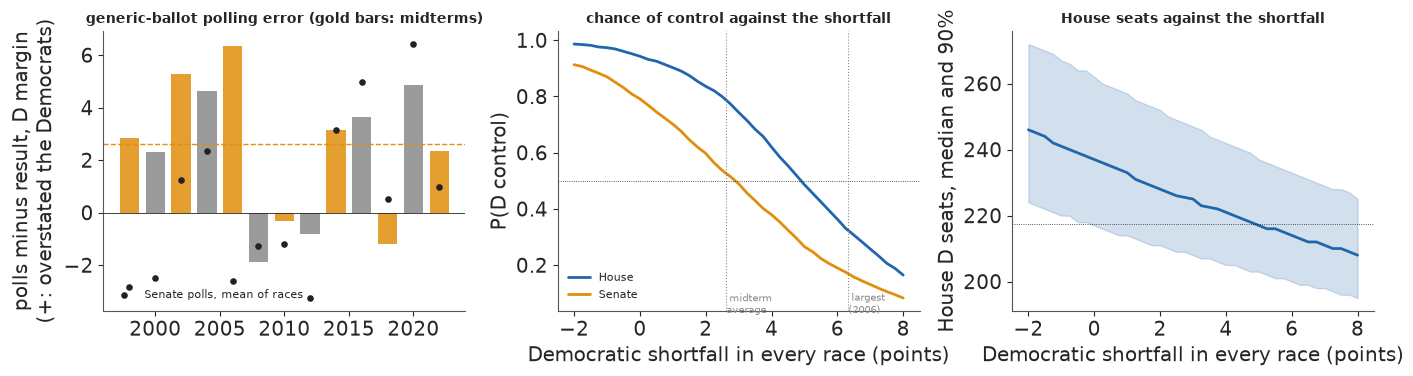

In [39]:
shortfalls = np.arange(-2, 8.01, 0.25)
rows = []
for dl in shortfalls:
    s_ = seats(fit26["d"], fit26["sim"] - dl)     # every race dl points less Democratic, in every draw
    sen_ = s_["S"] + notup["Democratic"] + notup["Independent"]
    rows.append({"shortfall": dl, "P(D House)": (s_["H"] >= 218).mean(), "P(D Senate)": (sen_ >= 51).mean(),
                 **{f"H q{int(100 * p_)}": np.quantile(s_["H"], p_) for p_ in (0.05, 0.5, 0.95)},
                 **{f"S q{int(100 * p_)}": np.quantile(sen_, p_) for p_ in (0.05, 0.5, 0.95)}})
sweep = pd.DataFrame(rows)
even = {k: float(np.interp(0.5, sweep[k].to_numpy()[::-1], sweep.shortfall.to_numpy()[::-1]))
        for k in ("P(D House)", "P(D Senate)")}           # P falls as the shortfall grows
print(sweep[sweep.shortfall.isin(np.arange(-1, 7))].round(2).to_string(index=False))
print(f"shortfall at which control is a coin flip: House {even['P(D House)']:.1f} points, "
      f"Senate {even['P(D Senate)']:.1f} points")
h0, h3 = (sweep.loc[sweep.shortfall == v, "H q50"].iat[0] for v in (0, 3))
print(f"median House seats: {h0:.0f} with no shortfall, {h3:.0f} with 3 points ({(h0 - h3) / 3:.1f} seats per point)")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
ax = axes[0]
ax.bar(hist.index, hist["generic ballot"], width=1.5, color=np.where(hist.midterm, GOLD, MUTED), alpha=0.85)
ax.scatter(hist.index, hist["Senate, mean of races"], color=INK, s=14, zorder=5, label="Senate polls, mean of races")
ax.axhline(0, color=INK, lw=0.6)
ax.axhline(MID_GEN[2026], color=GOLD, lw=1, ls="--")
ax.set_ylabel("polls minus result, D margin\n(+: overstated the Democrats)")
ax.set_title("generic-ballot polling error (gold bars: midterms)", fontsize=10)
ax.legend(fontsize=8, loc="lower left")
ax = axes[1]
ax.plot(sweep.shortfall, sweep["P(D House)"], color=D_C, lw=2, label="House")
ax.plot(sweep.shortfall, sweep["P(D Senate)"], color=GOLD, lw=2, label="Senate")
for v, lab in ((MID_GEN[2026], "midterm\naverage"), (hist[hist.midterm]["generic ballot"].max(), "largest\n(2006)")):
    ax.axvline(v, color=MUTED, lw=0.8, ls=":")
    ax.text(v, 0.03, f" {lab}", fontsize=7, color=MUTED)
ax.axhline(0.5, color=INK, lw=0.6, ls=":")
ax.set_xlabel("Democratic shortfall in every race (points)")
ax.set_ylabel("P(D control)")
ax.set_title("chance of control against the shortfall", fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
ax.fill_between(sweep.shortfall, sweep["H q5"], sweep["H q95"], color=D_C, alpha=0.2)
ax.plot(sweep.shortfall, sweep["H q50"], color=D_C, lw=2)
ax.axhline(217.5, color=INK, lw=0.6, ls=":")
ax.set_xlabel("Democratic shortfall in every race (points)")
ax.set_ylabel("House D seats, median and 90%")
ax.set_title("House seats against the shortfall", fontsize=10)
fig.tight_layout();

The simplest test subtracts a fixed shortfall from every race in every draw. The result is what the
forecast would say if the Democrats did $\delta$ points worse everywhere than the model expects, which
is what an extra shared polling error of $\delta$ would do.

The House holds up. Each point of shortfall costs about 4 seats at the median (237 seats becomes 225 at 3
points). The chance of a Democratic majority falls from 0.94 to 0.84 at 2 points and 0.74 at 3, and
becomes a coin flip only at 4.9 points, nearly twice the midterm average and close to the misses of 2002
and 2006. The Senate is fragile. Its median sits one seat above control, so a small shift moves the
deciding races in Iowa, Ohio and Alaska: 0.79 becomes 0.60 at 2 points, and control is a coin flip at 2.9,
about the size of an average midterm miss. If Democrats fall short of their polls by the historical
average, the House stays likely Democratic (about 0.8) and the Senate is a toss-up.

A uniform shift is the hardest case for the forecast, because every race moves in the same direction.
A real polling error also varies from race to race, and the model already carries that part, with an sd
of about 5.7 points.

In [40]:
t0 = time.time()
SHIFTED = {c: fit_cycle(c, bias_mean=MID_GEN[c]) for c in (2018, 2022, 2026)}
TIMES["shifted-prior fits"] = time.time() - t0
iv3 = lambda v, fmt: "{1:{f}} [{0:{f}}, {2:{f}}]".format(*np.quantile(v, [0.05, 0.5, 0.95]), f=fmt)  # noqa: E731
rows = []
for c in (2018, 2022, 2026):
    for lab, f in (("mean 0 (as frozen)", FITS[c, "full"] if c < 2026 else fit26),
                   (f"mean {MID_GEN[c]:+.1f}", SHIFTED[c])):
        row = {"cycle": c, "shared-error prior": lab, "div.": f["divergences"], "max r_hat": f["max r_hat"],
               "national": iv3(f["N"], "+.1f"), "House D": iv3(f["seats"]["H"], ".0f"),
               "P(D House)": round(float((f["seats"]["H"] >= 218).mean()), 2)}
        if c < 2026:
            sc, _, _ = race_scores(f["sim"], f["d"]["tm"].m.to_numpy())
            row.update({"actual N": round(MARGIN[c], 1),
                        "actual House": int((f["d"]["tgt"].query("office == 'H'").winner == "D").sum()),
                        "cover 90%": round(sc["cover 90%"], 3), "Brier": round(sc["Brier"], 4),
                        "log score": round(sc["log score"], 3), "wrong calls": sc["wrong calls"]})
        else:
            sen_ = f["seats"]["S"] + notup["Democratic"] + notup["Independent"]
            row.update({"Senate D": iv3(sen_, ".0f"), "P(D Senate)": round(float((sen_ >= 51).mean()), 2)})
        rows.append(row)
print(pd.DataFrame(rows).fillna("").to_string(index=False))
print(f"2026: the prior mean moved by {MID_GEN[2026]:+.1f}, the national median by "
      f"{np.median(SHIFTED[2026]['N']) - np.median(fit26['N']):+.1f}")

 cycle shared-error prior  div.  max r_hat           national        House D  P(D House) actual N actual House cover 90%   Brier log score wrong calls    Senate D P(D Senate)
  2018 mean 0 (as frozen)     0      1.006 +8.0 [+3.3, +12.6] 222 [203, 244]        0.65      8.8        235.0     0.934  0.0421    -0.133        26.0                        
  2018          mean +3.5     0      1.006 +5.2 [+0.5, +10.0] 211 [196, 232]        0.29      8.8        235.0     0.882  0.0525    -0.171        34.0                        
  2022 mean 0 (as frozen)     0      1.008  -2.0 [-6.8, +3.0] 204 [184, 222]        0.12     -2.7        213.0     0.924  0.0311    -0.101        21.0                        
  2022          mean +2.7     0      1.007  -4.2 [-9.0, +1.0] 196 [176, 216]        0.04     -2.7        213.0      0.89  0.0383    -0.122        27.0                        
  2026 mean 0 (as frozen)     0      1.011 +7.8 [+3.1, +12.7] 237 [217, 262]        0.94                                     

Subtracting a shift afterwards assumes the whole shortfall happens. To say "polls tend to overstate the
Democrats" in the model itself, move the prior mean of the shared error to the historical midterm
average and refit. As always, the average uses only midterms before the target: +3.5 for 2018, +2.7 for
2022 and +2.6 for 2026. The backtests can then judge the idea.

In 2026 the national median moves by 1.9 points, not by 2.6. The polls fix $N + b$, and the midterm prior
on $N$ pulls back, so the shift is shared in proportion to the prior variances: $2.6 \times
6.3^2/(6.3^2 + 3.3^2) \approx 2.0$. The refitted forecast gives 229 House seats (211 to 251) with
$P = 0.84$, and 51 Senate seats (47 to 55) with $P = 0.61$.

The backtests reject the shifted prior. In 2018 it puts the national margin at D+5.2 against an actual
D+8.8 and the House at 211 seats against 235, and gives a Democratic House a 0.29 chance (they won it).
Its race scores are worse on every measure: 88% coverage of the 90% intervals against 93%, a Brier score
of 0.053 against 0.042, and 34 wrong calls against 26. In 2022 it says R+4.2 against an actual R+2.7 and
196 seats against 213, and again every score is worse. That year the generic polls did overstate the
Democrats, by 2.3 points, but the midterm prior had already pulled the model's national estimate below
the polls, and the shifted prior pulled it too far. In both backtests the Democrats did better than the
unshifted model expected, not worse: the same lean as the PITs and the wrong calls in section 4.

So the tendency is real in the generic-ballot record, but it is small next to the swings from year to
year. Part of it is already absorbed by a midterm prior that is less enthusiastic than the polls, and two
backtests give no support for building in more. The question that matters on election night is how large
a shortfall would change the answer: about 5 points for the House and about 3 for the Senate.

### 7.2 The spending nowcast

In [41]:
late26 = predict_late(LATE_FIT["both -> 2026"], CT[2026])
ie26, ie26_seen = ie_nowcast(IE_FIT["both -> 2026"], 2026)
known26 = CT[2026].disb_known.sum()
cand26 = known26 + late26.sum(1)
all26 = cand26 + ie26
f3 = lambda v: f"{np.quantile(v, 0.5) / 1e9:.2f} [{np.quantile(v, 0.05) / 1e9:.2f}, {np.quantile(v, 0.95) / 1e9:.2f}]"  # noqa: E731
g3 = lambda v: f"{v[1] / 1e9:.2f} [{v[0] / 1e9:.2f}, {v[2] / 1e9:.2f}]"  # noqa: E731
fs1, fs = FROZEN1["spending_nowcast"], FROZEN["spending_nowcast"]
nc = pd.DataFrame({
    "v1 (pre-registered)": [f"{fs1['candidates_known_to_12G'] / 1e9:.2f}", g3(fs1["candidates_late_q05_q50_q95"]),
                            g3(fs1["candidates_total_q05_q50_q95"]),
                            f"{fs1['ie_seen_by_eve'] / 1e9:.2f} + {fs1['ie_unseen_estimate'] / 1e6:.0f}M (point)",
                            g3(fs1["all_q05_q50_q95"]) + " (no IE spread)", fs1["n_candidates"]],
    "v2 (corrected)": [f"{fs['candidates_known_to_12G'] / 1e9:.2f}", g3(fs["candidates_late_q05_q50_q95"]),
                       g3(fs["candidates_total_q05_q50_q95"]),
                       f"{fs['ie_seen_by_eve'] / 1e9:.2f} + {fs['ie_unseen_q05_q50_q95'][1] / 1e6:.0f}M "
                       f"[{fs['ie_unseen_q05_q50_q95'][0] / 1e6:.0f}, {fs['ie_unseen_q05_q50_q95'][2] / 1e6:.0f}]",
                       g3(fs["all_q05_q50_q95"]), fs["n_candidates"]],
    "this run": [f"{known26 / 1e9:.2f}", f3(late26.sum(1)), f3(cand26),
                 f"{ie26_seen / 1e9:.2f} + {np.median(ie26 - ie26_seen) / 1e6:.0f}M "
                 f"[{np.quantile(ie26 - ie26_seen, 0.05) / 1e6:.0f}, {np.quantile(ie26 - ie26_seen, 0.95) / 1e6:.0f}]",
                 f3(all26), len(CT[2026])]},
    index=["nominees, filed by the eve ($B)", "nominees, late ($B)", "nominees, total ($B)",
           "independent expenditures ($B)", "all ($B)", "nominees in the table"])
print("2026 spending nowcast: median [90%], through the post-general coverage (2026-11-23) for nominees")
print(nc.to_string())

2026 spending nowcast: median [90%], through the post-general coverage (2026-11-23) for nominees
                                              v1 (pre-registered)        v2 (corrected)              this run
nominees, filed by the eve ($B)                              2.39                  2.41                  2.41
nominees, late ($B)                             0.61 [0.40, 0.94]     0.64 [0.42, 0.97]     0.64 [0.42, 0.97]
nominees, total ($B)                            3.00 [2.79, 3.33]     3.05 [2.82, 3.38]     3.05 [2.82, 3.38]
independent expenditures ($B)                  3.17 + 22M (point)  3.17 + 49M [20, 124]  3.17 + 49M [20, 124]
all ($B)                         6.20 [5.99, 6.52] (no IE spread)     6.28 [6.04, 6.62]     6.28 [6.04, 6.62]
nominees in the table                                         860                   863                   863


In the corrected freeze, nominees had filed \$2.41B by the eve, and their late spending through 23
November is nowcast at \$0.64B (90% interval 0.42 to 0.97), for a nominee total of \$3.05B (2.82 to 3.38).
Outside groups had filed \$3.17B, plus an estimated \$49M not yet on file (20 to 124). All together,
**\$6.28B (6.04 to 6.62)**, against about \$4.4B in 2022. v1 said \$6.20B (5.99 to 6.52), for three fewer
nominees, with a point estimate for the outside part, so its interval leaves out the IE uncertainty.
The interval is set almost entirely by the candidates' late spending, and as section 6 says, the
backtests over-predicted that part in both cycles.

The 2026 outside total rests partly on a few very large filings, among them a Texas group's media buys
of \$20-28M each, split between support for one Senate nominee and opposition to the other in the same
filing. The items are distinct in the file and add up to the spender's own total, but whether a
contrast ad was counted on both sides cannot be checked from the filings.

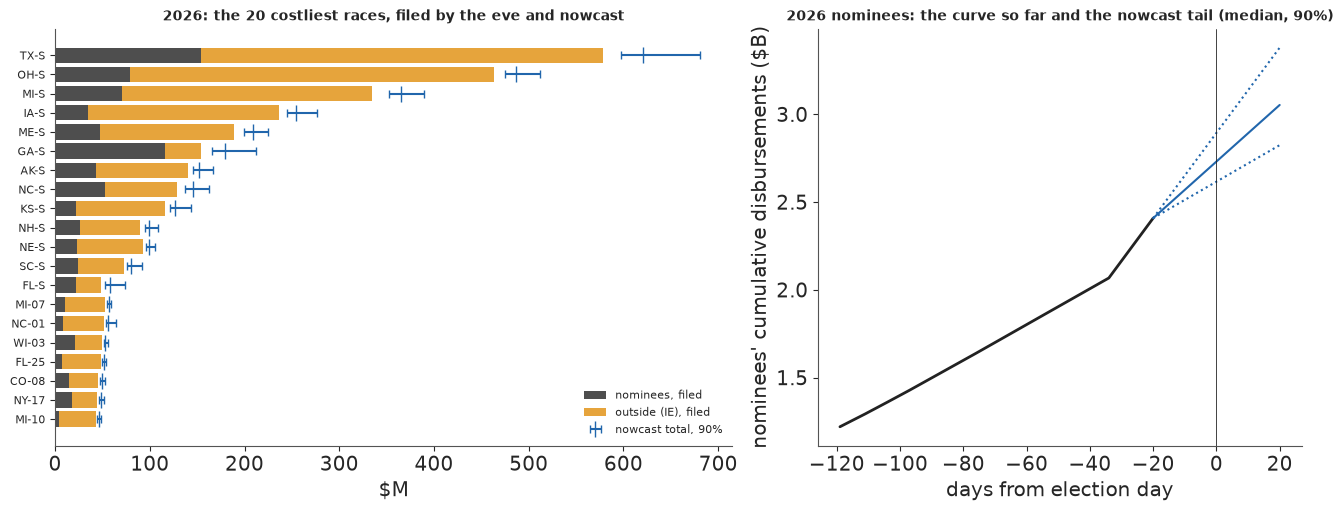

In [42]:
races26, draws26 = race_totals(2026, late26, CT[2026], ie26)
ord_ = np.argsort(-np.median(draws26, 0))[:20]
f26 = ie[(ie.cycle == 2026) & (ie.version == "eve")]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), width_ratios=[1.4, 1])
ax = axes[0]
for k, i in enumerate(ord_):
    rc = races26[i]
    known_c = CT[2026].disb_known[CT[2026].race == rc].sum() / 1e6
    ie_c = f26.amt[f26.race == rc].sum() / 1e6
    lo, mid, hi = np.quantile(draws26[:, i], [0.05, 0.5, 0.95]) / 1e6
    ax.barh(k, known_c, color=INK, alpha=0.8, label="nominees, filed" if k == 0 else None)
    ax.barh(k, ie_c, left=known_c, color=GOLD, alpha=0.8, label="outside (IE), filed" if k == 0 else None)
    ax.errorbar(mid, k, xerr=[[mid - lo], [hi - mid]], fmt="|", color=D_C, ms=12, capsize=3,
                label="nowcast total, 90%" if k == 0 else None)
ax.set_yticks(range(len(ord_)), [races26[i] for i in ord_], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("$M")
ax.legend(fontsize=8, loc="lower right")
ax.set_title("2026: the 20 costliest races, filed by the eve and nowcast", fontsize=10)
ax = axes[1]
elec = pd.Timestamp(ELEC[2026])
w = spend_window(2026)
days, kn = cumulative(w, elec)
last = SPEND[2026]["curve_known_last"]
ax.plot(days[(days <= last) & (days > -120)], kn[(days <= last) & (days > -120)] / 1e9, color=INK, lw=2, label="filed by the eve")
# the tail drawn as the 2022 shape of the late period, scaled to each draw's late total
w22 = spend_window(2022)
d22, f22 = cumulative(w22, pd.Timestamp(ELEC[2022]))
last22 = SPEND[2022]["curve_known_last"]
tail = (f22 - f22[d22 == last22]) / (f22[-1] - f22[d22 == last22])
sel = d22 >= last22
qs = np.quantile(late26.sum(1), [0.05, 0.5, 0.95])
for qv, ls in zip(qs, (":", "-", ":")):
    ax.plot(d22[sel], (kn[days == last] + qv * tail[sel]) / 1e9, color=D_C, ls=ls, lw=1.5)
ax.axvline(0, color=INK, lw=0.6)
ax.set_xlabel("days from election day")
ax.set_ylabel("nominees' cumulative disbursements ($B)")
ax.set_title("2026 nominees: the curve so far and the nowcast tail (median, 90%)", fontsize=10);

The costliest races are Senate races, led by Texas, Ohio and Michigan, where outside money (gold) dwarfs
what the nominees spent. The right panel draws the nowcast tail with the shape of 2022's last weeks.

## 8 · Scoring 2026, later

A frozen forecast is worth something only if it is scored the same way whatever happens. The scorer
takes a frozen file and a table of results (race and margin, with the seat totals and the national
margin attached). It reports the 80% coverage of race margins, the Brier score of the race chances and
the wrong calls; whether the seat totals and the national margin fall in their frozen 90% intervals;
the Brier and log scores of the chances of House and Senate control; and whether the nominees' 30G
spending falls in its frozen interval. It runs first on the 2018 and 2022 backtests, written in the
same format.

In [43]:
def score_frozen(frozen, results, nominee_late=None):
    """Score a frozen forecast dict against results.

    results: a DataFrame with race and margin (D minus R, points); its attrs may hold "House seats" (D seats),
    "Senate seats" (on the same definition as the frozen file: for 2026 the D caucus including the 34 seats
    not up; for the backtests the seats up only) and "N" (national House margin). nominee_late: the
    nominees' 30G disbursements in dollars."""
    fz_ = pd.DataFrame(frozen["races"]).merge(results, on="race")
    y = fz_.margin.to_numpy()
    out = {"races scored": len(fz_),
           "80% cover": float(np.mean((y >= fz_.q10) & (y <= fz_.q90))),
           "Brier": float(np.mean((fz_.pD - (y > 0)) ** 2)),
           "wrong calls": int(np.sum((fz_.pD > 0.5) != (y > 0))),
           "wrong calls, 0.2 < P(D) < 0.8": int(np.sum(((fz_.pD > 0.5) != (y > 0)) & (np.abs(fz_.pD - 0.5) < 0.3)))}
    for off, key, need in (("H", "House", 218), ("S", "Senate", 51)):
        if f"{key} seats" in results.attrs:
            seats_ = results.attrs[f"{key} seats"]
            lo, _, hi = frozen["seats"][off]["D_seats_q05_q50_q95"]
            out[f"{key} seats in 90%"] = bool(lo <= seats_ <= hi)
            p = frozen["seats"][off].get("P_D_control")
            if p is not None and (off == "H" or results.attrs.get("Senate counts all seats")):
                won = float(seats_ >= need)
                out[f"{key} control: Brier"] = round((p - won) ** 2, 4)
                out[f"{key} control: log score"] = round(float(np.log(max(p if won else 1 - p, 1e-6))), 3)
    if "N" in results.attrs:
        lo, _, hi = frozen["seats"]["N_q05_q50_q95"]
        out["national margin in 90%"] = bool(lo <= results.attrs["N"] <= hi)
    if nominee_late is not None:
        lo, _, hi = frozen["spending_nowcast"]["candidates_late_q05_q50_q95"]
        out["late spending in 90%"] = bool(lo <= nominee_late <= hi)
    return out


def as_frozen(f, cycle):
    """Write a backtest fit in the frozen file's format, so the same scorer runs on 2018 and 2022."""
    tm = f["d"]["tm"]
    q10, med, q90 = np.quantile(f["sim"], [0.1, 0.5, 0.9], 0)
    return {"races": pd.DataFrame({"race": tm.race, "office": tm.office, "pD": (f["sim"] > 0).mean(0), "pred": med,
                                   "q10": q10, "q90": q90}).to_dict("records"),
            "seats": {"H": {"D_seats_q05_q50_q95": list(np.quantile(f["seats"]["H"], [0.05, 0.5, 0.95])),
                            "P_D_control": float((f["seats"]["H"] >= 218).mean())},
                      "S": {"D_seats_q05_q50_q95": list(np.quantile(f["seats"]["S"], [0.05, 0.5, 0.95]))},
                      "N_q05_q50_q95": list(np.quantile(f["N"], [0.05, 0.5, 0.95]))}}


for c in (2018, 2022):
    f = FITS[c, "full"]
    res = f["d"]["tm"][["race"]].assign(margin=f["d"]["tm"].m.to_numpy())
    res.attrs = {"House seats": int((f["d"]["tgt"].query("office == 'H'").winner == "D").sum()),
                 "Senate seats": int((f["d"]["tgt"].query("office == 'S'").winner == "D").sum()), "N": MARGIN[c]}
    print(c, score_frozen(as_frozen(f, c), res))

2018 {'races scored': 424, '80% cover': 0.8537735849056604, 'Brier': 0.042137985849056606, 'wrong calls': 26, 'wrong calls, 0.2 < P(D) < 0.8': 18, 'House seats in 90%': True, 'House control: Brier': 0.1225, 'House control: log score': -0.431, 'Senate seats in 90%': True, 'national margin in 90%': True}
2022 {'races scored': 436, '80% cover': 0.8325688073394495, 'Brier': 0.031116297018348622, 'wrong calls': 21, 'wrong calls, 0.2 < P(D) < 0.8': 18, 'House seats in 90%': True, 'House control: Brier': 0.0146, 'House control: log score': -0.129, 'Senate seats in 90%': True, 'national margin in 90%': True}


It reproduces the backtest: 80% intervals covered 85% and 83% of races, 18 wrong calls each year among
races given a 20-80% chance, every seat total and national margin inside its 90% interval, and a Brier
score for House control of 0.12 in 2018 and 0.01 in 2022. In the backtests the Senate count is the seats
up, which says nothing about control, so only the House control is scored there.

For 2026 the cell scores v1 and v2 side by side once two files exist: `e94_results_2026.csv` (race,
margin) and `e94_results_2026_totals.json` with "House seats", "Senate seats" (the Democratic caucus
including the 34 seats not up, as in the frozen files) and "N". The late-spending check needs
`e94_30g_2026.csv` from the 30G reports due on 3 December; it sums v2's nominees, three more than v1's.

In [44]:
RESULTS_2026 = data.DATA_DIR / "e94_results_2026.csv"         # race, margin: does not exist on 2026-11-03
TOTALS_2026 = data.DATA_DIR / "e94_results_2026_totals.json"  # House seats, Senate seats (D caucus incl. not up), N
LATE_2026 = data.DATA_DIR / "e94_30g_2026.csv"                # cand_id, disb: post-general reports due 2026-12-03
if RESULTS_2026.exists() and TOTALS_2026.exists():
    res26 = pd.read_csv(RESULTS_2026)
    res26.attrs = {**json.load(open(TOTALS_2026)), "Senate counts all seats": True}
    late_true = None
    if LATE_2026.exists():
        g30 = pd.read_csv(LATE_2026)
        late_true = float(g30[g30.cand_id.isin(FROZEN["spending_nowcast"]["late_per_candidate_q05_q50_q95"])].disb.sum())
    for lab, fz_ in (("v1 (pre-registered)", FROZEN1), ("v2 (corrected)", FROZEN)):
        print(f"2026 {lab}:", score_frozen(fz_, res26, late_true))
else:
    print("2026 election results: not yet available. Both frozen forecasts wait to be scored.")
if not LATE_2026.exists():
    print("2026 post-general (30G) reports: not yet available (due 2026-12-03).")
TIMES["total"] = time.time() - T_START
print({k: round(v) for k, v in TIMES.items()})

2026 election results: not yet available. Both frozen forecasts wait to be scored.
2026 post-general (30G) reports: not yet available (due 2026-12-03).
{'2026 fits': 47, 'backtest fits': 72, 'rematch fit': 3, 'IE lag fits': 7, 'late-spending fits': 12, 'shifted-prior fits': 58, 'total': 221}


## Summary

* **Information is ragged.** In 2026, 97 of 416 contested House districts have a race poll, 42 of
  them only partisan ones, and 30 of 70 close districts have none. Fundamentals carry the rest.
* **The national environment** came from a midterm prior updated by a weekly walk of generic polls
  with house effects and a shared polling error. Sampled directly, the margin and the shared error
  formed a ridge (ESS about 300); rotated as in E40, ESS 5,500.
* **The backtests held.** Learned on earlier cycles only, the full model's 90% intervals covered 93% and
  92% of race margins, and its seat intervals contained the results (222 [203, 244] against 235 House
  seats in 2018, 204 [184, 222] against 213 in 2022). Both cycles put the Democrats a few seats short.
* **Money is a signal, not a lever.** The naive regression shows Jacobson's paradox because money
  follows close races. In 232 rematches, doubling the Democrat's spending is worth about +0.7 points of
  share: a small effect, and if anything an upper bound.
* **Spending can be nowcast, with care.** Outside money is 99% on file by the eve; candidates' last
  five weeks (about a fifth of their spending) arrive a month later. A late-spending model from the 12G
  burn rate and cash on hand covered 96% of race totals. On national totals the evidence is thin: two
  totals, both over-predicted (\$481M against \$434M, \$623M against \$443M), only one of them a forward
  test, with the error family and the cycle shift chosen after the pilot had seen them.
* **2026 is frozen twice and waits.** The corrected freeze (v2): D+7.8 nationally (3.0 to 12.9), 236
  Democratic House seats (217 to 262, P = 0.94), 52 Democratic-caucus Senate seats (48 to 56, P = 0.78),
  and \$6.28B of spending (6.04 to 6.62), \$0.64B of it nominees' late spending not yet reported. The
  pre-registered v1 said D+7.9, 236 seats (P = 0.95), 52 seats (P = 0.83) and \$6.20B; it counted
  nominees without a matched FEC ID as raising nothing. Both were committed before the polls closed,
  and the scoring code prints "not yet available" until the results are in.
* **The Senate depends more than the House on whether the polls lean Democratic.** Generic-ballot polls
  overstated the Democrats in 5 of 7 midterms since 1998, by 2.6 points on average. With a uniform
  shortfall, House control becomes a coin flip at 4.9 points and Senate control at 2.9. Building the
  average into the prior moves 2026 to 229 seats ($P = 0.84$) and Senate $P = 0.61$, but it made both the
  2018 and 2022 backtests worse.

## Try it yourself

1. **Thin the 2026 snapshots.** Keep one snapshot per aggregator every other week, or one average of all
   aggregators per week, and refit 2026. How much does the national interval widen, and how many House
   seats does the median move? Then do the same to the aggregate-only backtests and check whether the
   wider version is better calibrated on 2018 and 2022.
2. **A district poll model of its own.** Partisan polls are few in 2018 but many in 2026. Give polls
   with a D or R mark their own excess noise as well as a sponsor shift, and let the sponsor shift vary
   by party. Does the 2022 PIT (which leaned high) flatten, and how much do the chances in the 30
   closest 2026 races change?
3. **The whole spending curve.** Replace the late-spending model by a hierarchical growth curve for each
   race over the cycle (for example a log-logistic cumulative curve per race whose midpoint and final
   total pool by office and competitiveness), fitted to every report received by the eve. Does it beat
   the tail model on the 2018 and 2022 backtests, and does its interval for 2026 agree?